# Лабораторная работа №1: Решение задачи классификации методом k-ближайших соседей (k-NN)

**Студент:** Долов Вячеслав  
**Дисциплина:** Машинное обучение  
**Датасет:** Anime Dataset 2023 (`anime-dataset-2023.csv`)  

---

## Введение и цель работы

### Цель работы
Освоение полного цикла первичной обработки данных (Data Preprocessing), разведочного анализа (EDA) и построения базовой модели машинного обучения (классификатора $k$-ближайших соседей) на примере реального набора данных.

### Постановка задачи
В данной работе решается задача **многоклассовой классификации**. На основе производственных, метрических и рейтинговых характеристик аниме необходимо предсказать его формат выпуска (`Type`).

* **Целевая переменная (`y`):** Признак `Type`, принимающий значения основных форматов: `TV` (сериалы), `Movie` (фильмы), `OVA`, `ONA`, `Special` (спешлы) и `Music` (музыкальные клипы).
* **Признаковое пространство (`X`):** числовые характеристики - оценка (`Score`), число серий (`Episodes`), длительность (`Duration_min`), число оценивших (`Scored By`), число добавивших в список (`Members`), число добавлений в избранное (`Favorites`), места в рейтингах (`Rank`, `Popularity`); категориальные - источник (`Source`), возрастной рейтинг (`Rating`), статус (`Status`); а также жанры (`Genres`).

---

### Описание данных

Таблица содержит данные о 24 905 аниме с сайта MyAnimeList: 24 признака и 6 классов целевой переменной (после удаления объектов без класса остаётся 24 831 объект). Признаки:

| Признак | Описание | Тип |
|---|---|---|
| `anime_id` | уникальный номер тайтла | идентификатор |
| `Name`, `English name`, `Other name` | название на оригинальном, английском и родном языках | текст |
| `Synopsis` | краткое описание сюжета | текст |
| `Image URL` | ссылка на постер | текст |
| `Score` | средняя оценка пользователей (от 1 до 10) | числовой |
| `Scored By` | число пользователей, поставивших оценку | числовой |
| `Members` | число пользователей, добавивших тайтл в свой список | числовой |
| `Favorites` | число добавлений в избранное | числовой |
| `Rank` | место в рейтинге по оценке | числовой |
| `Popularity` | место в рейтинге по популярности | числовой |
| `Episodes` | число серий | числовой |
| `Duration` | длительность серии или фильма | текст («24 min per ep») |
| `Genres` | жанры через запятую | категориальный (несколько значений) |
| `Source` | первоисточник (манга, оригинал, игра и т.д.) | категориальный |
| `Rating` | возрастной рейтинг | категориальный |
| `Status` | статус выхода (вышло, выходит, не вышло) | категориальный |
| `Aired`, `Premiered` | даты выхода, сезон и год премьеры | текст |
| `Producers`, `Licensors`, `Studios` | компании | список названий |
| `Type` | формат выпуска | **целевая переменная** (категориальная) |

Как видно из таблицы, предсказывать нужно категориальный признак, поэтому это задача классификации.

## Пункт 1: Загрузка данных и первичная обработка

Загрузка набора данных из формата CSV. На данном этапе выполняется считывание таблицы, замена текстовых маркеров отсутствующих данных (`UNKNOWN`) на значение `NaN` (Not a Number), приведение числовых столбцов к корректному типу, отбор объектов шести основных классов целевой переменной и перевод длительности из текста в число.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

In [2]:
# 1. Загрузка данных
df = pd.read_csv('anime-dataset-2023.csv')
print(f"Исходная размерность: {df.shape[0]} строк, {df.shape[1]} столбцов")

# Замена текстовых заполнителей пропусков 'UNKNOWN' на NaN
df = df.replace('UNKNOWN', np.nan)

# Какие значения принимает целевая переменная
print(df['Type'].value_counts(dropna=False))

Исходная размерность: 24905 строк, 24 столбцов
Type
TV         7597
Movie      4381
OVA        4076
ONA        3533
Music      2686
Special    2558
NaN          74
Name: count, dtype: int64


В `Type` встречаются только шесть ожидаемых значений. У 74 объектов (≈0.3%) значение отсутствует: для них неизвестен класс, поэтому они удаляются.

In [3]:
# Удаляем объекты без целевой переменной и оставляем только 6 основных классов
main_classes = ['TV', 'Movie', 'OVA', 'ONA', 'Special', 'Music']
df = df[df['Type'].isin(main_classes)].reset_index(drop=True)

# Приведение типов для колонок, содержавших 'UNKNOWN'
num_cols_to_convert = ['Score', 'Episodes', 'Rank', 'Popularity', 'Scored By']
for col in num_cols_to_convert:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(f"Размерность после первичной очистки: {df.shape[0]} строк, {df.shape[1]} столбцов.")
df.head()

Размерность после первичной очистки: 24831 строк, 24 столбцов.


,anime_id,Name,English name,Other name,Score,Genres,Synopsis,Type,Episodes,Aired,Premiered,Status,Producers,Licensors,Studios,Source,Duration,Rating,Rank,Popularity,Favorites,Scored By,Members,Image URL
0,1,Cowboy Bebop,Cowboy Bebop,カウボーイビバップ,8.75,"Action, Award Winning, Sci-Fi","Crime is timeless. By the year 2071, humanity ...",TV,26.0,"Apr 3, 1998 to Apr 24, 1999",spring 1998,Finished Airing,Bandai Visual,"Funimation, Bandai Entertainment",Sunrise,Original,24 min per ep,R - 17+ (violence & profanity),41.0,43,78525,914193.0,1771505,https://cdn.myanimelist.net/images/anime/4/196...
1,5,Cowboy Bebop: Tengoku no Tobira,Cowboy Bebop: The Movie,カウボーイビバップ 天国の扉,8.38,"Action, Sci-Fi","Another day, another bounty—such is the life o...",Movie,1.0,"Sep 1, 2001",NaN,Finished Airing,"Sunrise, Bandai Visual",Sony Pictures Entertainment,Bones,Original,1 hr 55 min,R - 17+ (violence & profanity),189.0,602,1448,206248.0,360978,https://cdn.myanimelist.net/images/anime/1439/...
2,6,Trigun,Trigun,トライガン,8.22,"Action, Adventure, Sci-Fi","Vash the Stampede is the man with a $$60,000,0...",TV,26.0,"Apr 1, 1998 to Sep 30, 1998",spring 1998,Finished Airing,Victor Entertainment,"Funimation, Geneon Entertainment USA",Madhouse,Manga,24 min per ep,PG-13 - Teens 13 or older,328.0,246,15035,356739.0,727252,https://cdn.myanimelist.net/images/anime/7/203...
3,7,Witch Hunter Robin,Witch Hunter Robin,Witch Hunter ROBIN (ウイッチハンターロビン),7.25,"Action, Drama, Mystery, Supernatural",Robin Sena is a powerful craft user drafted in...,TV,26.0,"Jul 3, 2002 to Dec 25, 2002",summer 2002,Finished Airing,"Bandai Visual, Dentsu, Victor Entertainment, T...","Funimation, Bandai Entertainment",Sunrise,Original,25 min per ep,PG-13 - Teens 13 or older,2764.0,1795,613,42829.0,111931,https://cdn.myanimelist.net/images/anime/10/19...
4,8,Bouken Ou Beet,Beet the Vandel Buster,冒険王ビィト,6.94,"Adventure, Fantasy, Supernatural",It is the dark century and the people are suff...,TV,52.0,"Sep 30, 2004 to Sep 29, 2005",fall 2004,Finished Airing,"TV Tokyo, Dentsu",Illumitoon Entertainment,Toei Animation,Manga,23 min per ep,PG - Children,4240.0,5126,14,6413.0,15001,https://cdn.myanimelist.net/images/anime/7/215...


In [4]:
# Типы данных и число непустых значений
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24831 entries, 0 to 24830
Data columns (total 24 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   anime_id      24831 non-null  int64  
 1   Name          24831 non-null  object 
 2   English name  10315 non-null  object 
 3   Other name    24707 non-null  object 
 4   Score         15691 non-null  float64
 5   Genres        19917 non-null  object 
 6   Synopsis      24831 non-null  object 
 7   Type          24831 non-null  object 
 8   Episodes      24287 non-null  float64
 9   Aired         24831 non-null  object 
 10  Premiered     5506 non-null   object 
 11  Status        24831 non-null  object 
 12  Producers     11542 non-null  object 
 13  Licensors     4735 non-null   object 
 14  Studios       14366 non-null  object 
 15  Source        24831 non-null  object 
 16  Duration      24831 non-null  object 
 17  Rating        24220 non-null  object 
 18  Rank          20274 non-nu

Столбец `Duration` содержит текст («24 min per ep», «1 hr 55 min»). Для использования в модели переводим его в число - длительность в минутах (`Duration_min`). Преобразование выполняется построчно и не использует статистики по данным, поэтому утечки информации не возникает. Для значений без числа (например, `Unknown`) результатом будет пропуск (таких 591), он будет обработан в п. 5.

In [5]:
import re

def parse_duration(text):
    """'1 hr. 55 min.' или '24 min. per ep.' -> минуты"""
    if pd.isna(text):
        return np.nan
    h = re.search(r'(\d+)\s*hr', text)
    m = re.search(r'(\d+)\s*min', text)
    s = re.search(r'(\d+)\s*sec', text)
    if not (h or m or s):
        return np.nan
    return (int(h.group(1)) * 60 if h else 0) + (int(m.group(1)) if m else 0) + (int(s.group(1)) / 60 if s else 0)

df['Duration_min'] = df['Duration'].apply(parse_duration)
print('Пропусков в Duration_min:', df['Duration_min'].isna().sum())
df[['Duration', 'Duration_min']].sample(8, random_state=1)

Пропусков в Duration_min: 591


,Duration,Duration_min
12190,3 min,3.0
13356,2 min,2.0
5186,25 min per ep,25.0
3854,26 min per ep,26.0
21534,13 min per ep,13.0
8996,3 min,3.0
12457,5 min,5.0
19398,10 min per ep,10.0


## Пункт 2: Разбиение на обучающую и тестовую выборки

Данные делятся на обучающую (75%) и тестовую (25%) выборки. Тестовая выборка «откладывается» и не используется при анализе данных, подборе параметров предобработки и обучении модели, чтобы оценка качества была честной (без утечки информации). Разбиение выполняется со **стратификацией** по `Type`: классы несбалансированы умеренно (самый большой класс примерно втрое больше самого малого), и стратификация сохраняет их пропорции в обеих выборках.

In [6]:
df_train, df_test = train_test_split(
    df, test_size=0.25, random_state=42, stratify=df['Type']
)

print(f"Обучающая выборка: {df_train.shape[0]} объектов")
print(f"Тестовая выборка:  {df_test.shape[0]} объектов")

# Проверка, что пропорции классов сохранились
pd.DataFrame({
    'train, %': (df_train['Type'].value_counts(normalize=True) * 100).round(2),
    'test, %':  (df_test['Type'].value_counts(normalize=True) * 100).round(2),
})

Обучающая выборка: 18623 объектов
Тестовая выборка:  6208 объектов


,"train, %","test, %"
Type,,
TV,30.60,30.59
Movie,17.64,17.64
OVA,16.42,16.41
ONA,14.23,14.22
Music,10.81,10.82
Special,10.30,10.31


## Пункт 3: Визуализация данных и основные характеристики

Разведочный анализ (EDA) проводится **только на обучающей выборке**. План:
1. Баланс классов целевой переменной.
2. Основные статистические характеристики числовых и категориальных признаков.
3. Распределения числовых признаков (гистограммы).
4. Распределения признаков по классам (ящики с усами).
5. Диаграммы рассеяния.
6. Корреляционная матрица.
7. Связь категориальных признаков с целевой переменной.

### 3.1 Баланс классов

Type
TV         5698
Movie      3286
OVA        3057
ONA        2650
Music      2014
Special    1918
Name: count, dtype: int64


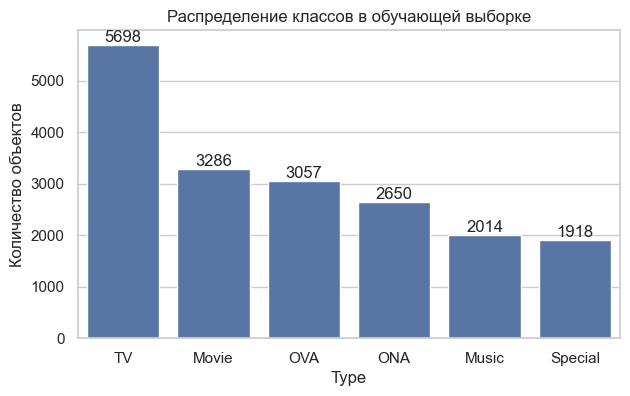

In [7]:
counts = df_train['Type'].value_counts()
print(counts)

plt.figure(figsize=(7, 4))
sns.barplot(x=counts.index, y=counts.values)
plt.xlabel('Type')
plt.ylabel('Количество объектов')
plt.title('Распределение классов в обучающей выборке')
for i, v in enumerate(counts.values):
    plt.text(i, v, str(v), ha='center', va='bottom')
plt.show()

**Интерпретация.** Классы представлены неравномерно: самый частый - `TV` (5698 объектов, ≈30.6%), самый редкий - `Special` (1918, ≈10.3%), отношение примерно 3:1. Дисбаланс умеренный, но учитывать его нужно: классификатор, всегда отвечающий `TV`, получил бы accuracy ≈ 30.6%. Это нижняя планка, с которой будем сравнивать модели. Поэтому помимо accuracy используем матрицу рассогласования и F1-меру по классам.

### 3.2 Основные характеристики

In [8]:
numeric_cols = ['Score', 'Episodes', 'Scored By', 'Members', 'Favorites', 'Rank', 'Popularity']
categorical_cols = ['Source', 'Rating', 'Status', 'Premiered']

# Среднее, разброс (std), квантили, min/max
df_train[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Score,11742.0,6.382954,0.927615,1.85,5.73,6.39,7.06,9.1
Episodes,18218.0,14.887639,44.562465,1.00,1.00,2.00,13.00,1818.0
Scored By,11742.0,29905.480327,117000.464985,100.00,385.00,1768.00,10751.00,2660903.0
Members,18623.0,36990.325297,156720.696683,0.00,208.50,1059.00,9366.00,3744541.0
Favorites,18623.0,440.645707,4643.349066,0.00,0.00,1.00,18.00,217606.0
Rank,15221.0,9997.170291,5863.474504,0.00,4896.00,9989.00,15098.00,20104.0
Popularity,18623.0,12298.682382,7187.217618,0.00,6048.00,12289.00,18526.50,24723.0


In [9]:
# Категориальные признаки: число уникальных значений и самое частое
df_train[categorical_cols].describe().T

,count,unique,top,freq
Source,18623,17,Original,7197
Rating,18167,6,PG-13 - Teens 13 or older,6357
Status,18623,3,Finished Airing,18056
Premiered,4127,238,spring 2017,66


**Интерпретация.**
- У всех признаков, кроме `Score`, `Rank` и `Popularity`, среднее намного больше медианы, то есть распределения сильно скошены вправо: `Episodes` (среднее 14.9, медиана 2, максимум 1818), `Scored By` (30 тыс. и 1768), `Members` (37 тыс. и 1059), `Favorites` (среднее 441, медиана 1, у 75% объектов не больше 18, максимум 217 606). Стандартное отклонение у них в 3-10 раз больше среднего, то есть разброс очень большой, а типичный тайтл малоизвестен.
- `Score` распределён симметрично (среднее 6.38, медиана 6.39, стандартное отклонение 0.93). `Rank` и `Popularity` имеют среднее, равное медиане, и равномерный разброс - это порядковые номера. Минимальное значение обоих равно 0, хотя нумерация должна начинаться с 1 (разберём в п. 4).
- Пропуски: оценка (`Score`, `Scored By`) есть у 11 742 из 18 623 объектов (63%), ранг - у 15 221, число серий - у 18 218.
- Категориальные признаки: у `Source` 17 значений, самое частое `Original` (7197, ≈39%); у `Rating` 6 значений, чаще всего `PG-13`; `Status` почти константен (`Finished Airing` у 97% объектов). У `Premiered` 238 разных значений и заполнено лишь 22% объектов, поэтому он использоваться не будет.

### 3.3 Гистограммы числовых признаков
Строим гистограммы всех числовых признаков. Идентификатор `anime_id` не рассматривается: это номер записи, он не несёт информации о типе аниме.

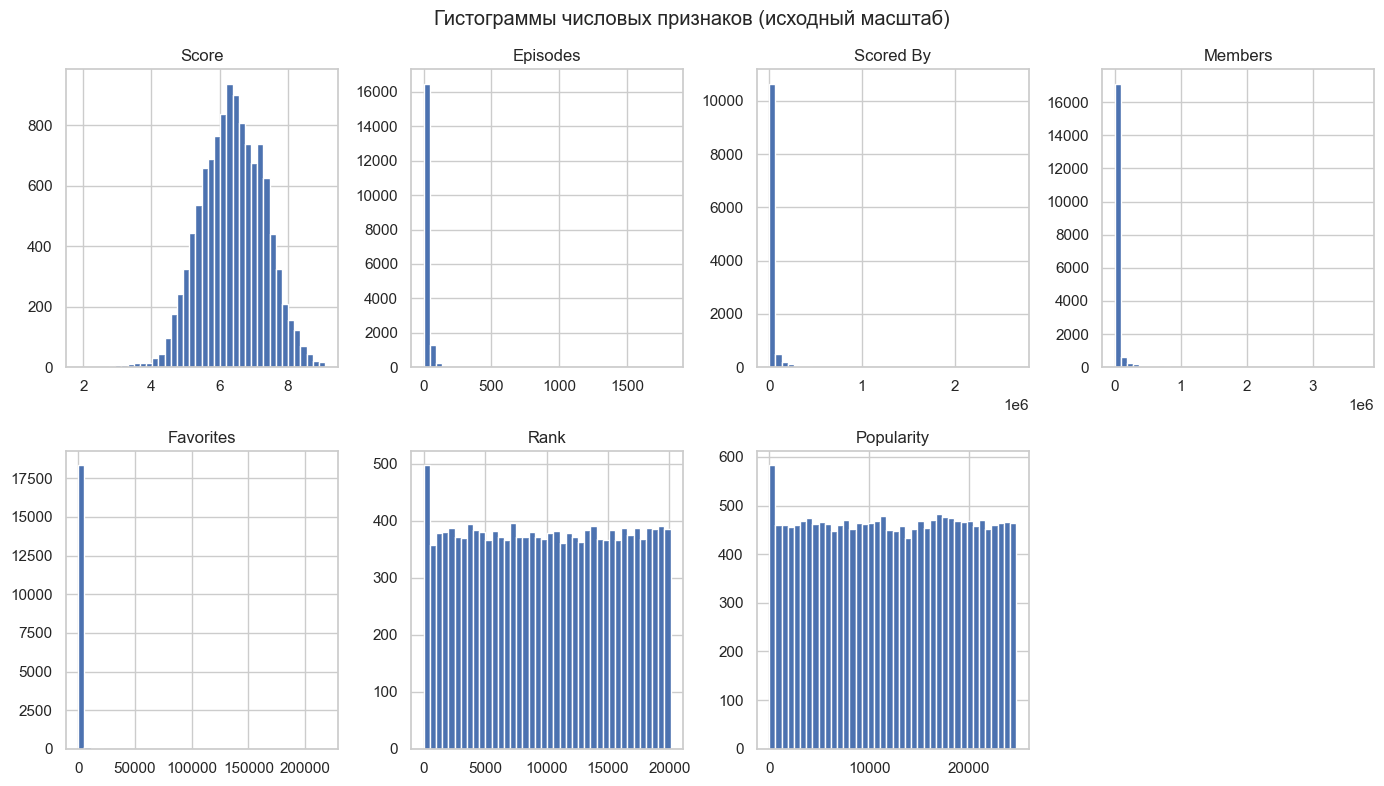

In [10]:
df_train[numeric_cols].hist(bins=40, figsize=(14, 8), layout=(2, 4))
plt.suptitle('Гистограммы числовых признаков (исходный масштаб)')
plt.tight_layout()
plt.show()

**Интерпретация.** `Score` распределён близко к нормальному (колокол с центром около 6.3-6.5). Признаки `Episodes`, `Scored By`, `Members`, `Favorites` имеют очень длинный правый хвост: почти все объекты сосредоточены у нуля, а редкие огромные значения (до ~1800 серий, до миллионов пользователей) растягивают ось, поэтому форма распределения не видна. `Rank` и `Popularity` распределены равномерно - это порядковые номера, и так и должно быть. Первый столбец у них заметно выше остальных (примерно на 120 объектов). Похоже, что там накопились нулевые значения, которые не могут быть реальным рангом; проверим это в п. 4.

Чтобы увидеть форму распределения скошенных признаков, построим их гистограммы после преобразования $\log(1+x)$: логарифм сжимает длинный хвост, а «+1» нужно, чтобы нули не давали $-\infty$.

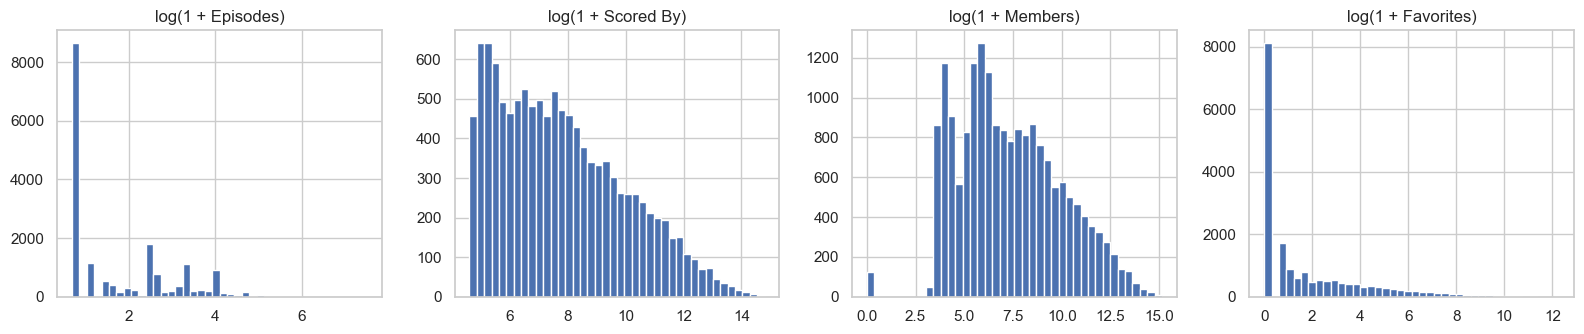

In [11]:
skewed_cols = ['Episodes', 'Scored By', 'Members', 'Favorites']

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, skewed_cols):
    ax.hist(np.log1p(df_train[col].dropna()), bins=40)
    ax.set_title(f'log(1 + {col})')
plt.tight_layout()
plt.show()

**Интерпретация.** После логарифмирования распределения стали компактными и «колоколообразными» (кроме `Episodes` и `Favorites`: у них много объектов с минимальным значением - 1 серия, 0 добавлений в избранное). Это значит, что для метода ближайших соседей, чувствительного к масштабу признаков, эти признаки лучше использовать в логарифмированном виде (вернёмся к этому в п. 7).

### 3.4 Распределения признаков по классам
Ящики с усами строим отдельно для каждого класса `Type`: так видно, какие признаки различают классы. Для скошенных признаков используем логарифм, как выше. Точки за «усами» - потенциальные выбросы.

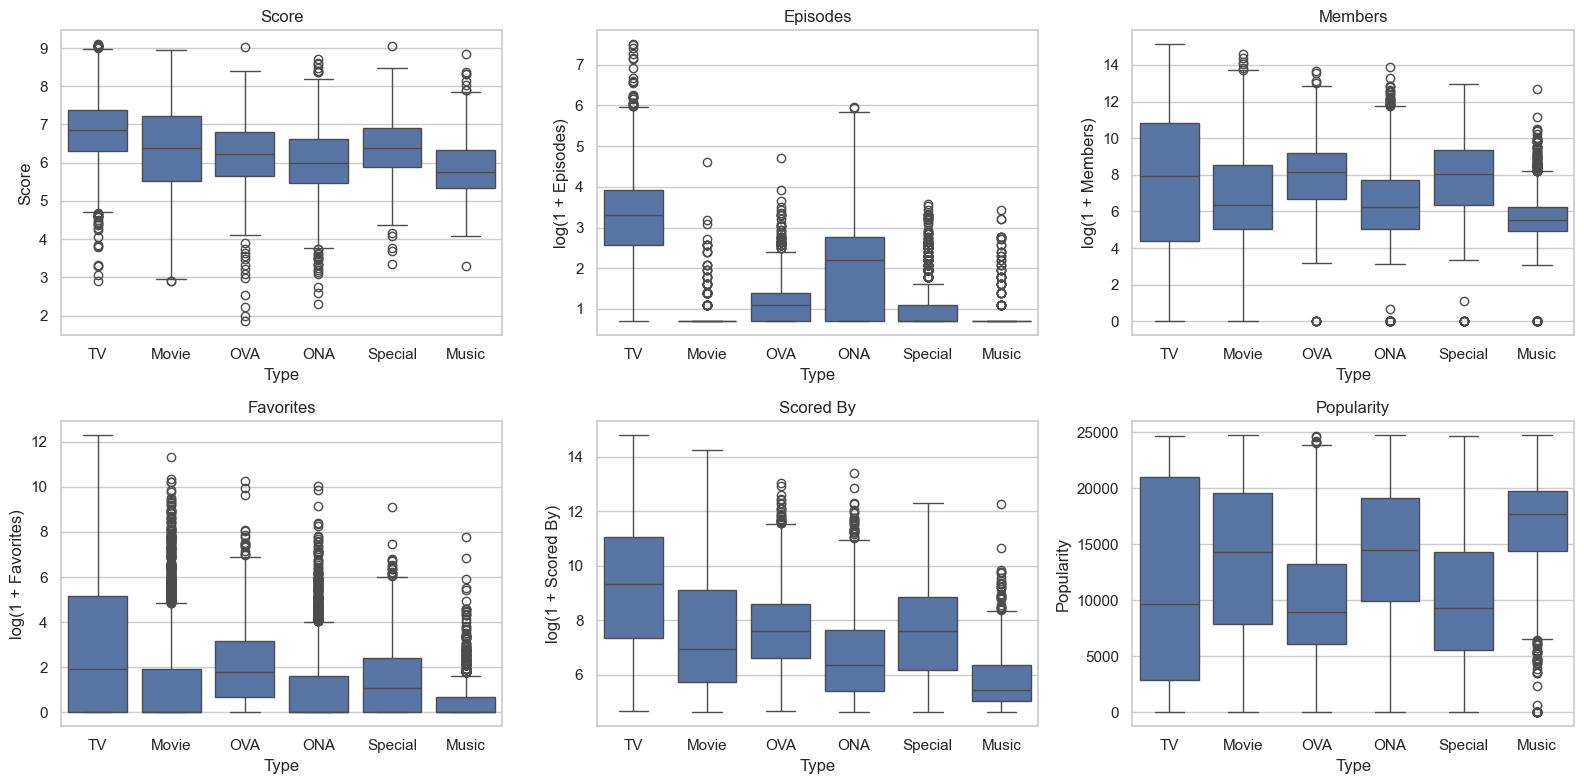

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
cols_for_box = ['Score', 'Episodes', 'Members', 'Favorites', 'Scored By', 'Popularity']
order = ['TV', 'Movie', 'OVA', 'ONA', 'Special', 'Music']

for ax, col in zip(axes.ravel(), cols_for_box):
    values = df_train[col]
    if col in ['Episodes', 'Members', 'Favorites', 'Scored By']:
        values = np.log1p(values)
        ax.set_ylabel(f'log(1 + {col})')
    sns.boxplot(x=df_train['Type'], y=values, order=order, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Интерпретация.**
- `Episodes` - самый информативный признак. У `Movie` и `Music` медиана равна 1 серии, у `Special` и `OVA` тоже в основном 1-2 серии. У `TV` медиана около 26 серий и очень большой разброс (до сотен серий). У `ONA` промежуточное положение (медиана около 8 серий).
- `Members`, `Scored By`, `Favorites`: у `Music` значения заметно ниже, чем у остальных классов; у `TV` самый широкий разброс и самые высокие значения. То есть клипы малоизвестны, а сериалы бывают как очень популярными, так и совсем незаметными.
- `Score`: медианы классов близки (от ≈5.8 у `Music` до ≈6.8 у `TV`), ящики сильно перекрываются, поэтому по оценке классы различаются слабо.
- `Popularity` - ранг (меньше = популярнее): у `Music` медиана самая высокая (то есть наименее популярны), у `OVA` и `Special` - самая низкая.
- Выбросов много (точки за усами) практически у всех признаков. Для `Episodes`, `Members`, `Favorites` это реальные значения (очень длинные сериалы, очень популярные тайтлы), а не ошибки.

Длительность `Duration_min` (минут на серию или на весь фильм) строим на логарифмической шкале, так как значения различаются на порядки: от клипов в несколько минут до полнометражных фильмов.

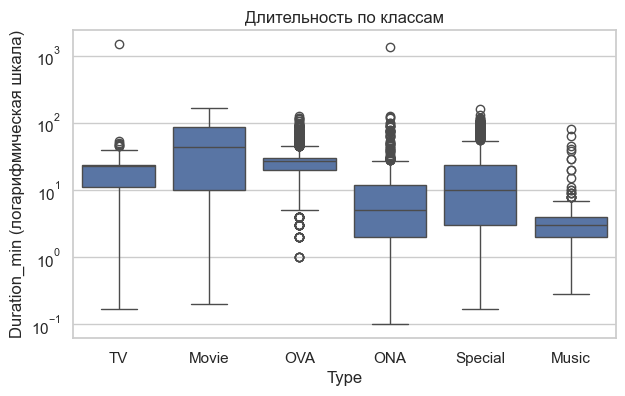

In [13]:
plt.figure(figsize=(7, 4))
sns.boxplot(x=df_train['Type'], y=df_train['Duration_min'], order=order)
plt.yscale('log')
plt.ylabel('Duration_min (логарифмическая шкала)')
plt.title('Длительность по классам')
plt.show()

**Интерпретация.** Длительность хорошо разделяет классы по порядку величины:
- `Music` - самые короткие (медиана около 3 минут, ящик очень узкий), `ONA` - медиана около 5 минут, `Special` - около 10 минут при большом разбросе;
- у `TV` и `OVA` типичная длительность серии 20-30 минут (медиана `TV` около 24, `OVA` около 28), поэтому по длительности они почти не различаются; отличает их число серий;
- у `Movie` самая большая длительность (медиана около 45 минут, ящик от 10 до 90 минут, максимум около 170 минут) и самый широкий разброс: в классе есть и короткие, и полнометражные фильмы;
- два значения порядка 1300-1500 минут (по одному у `TV` и `ONA`) - ошибки данных (разобраны в п. 4).

### 3.5 Диаграммы рассеяния
Сначала строим диаграммы для пар признаков с раскраской по классам (при необходимости - в логарифмическом масштабе), затем матрицу всех парных диаграмм.

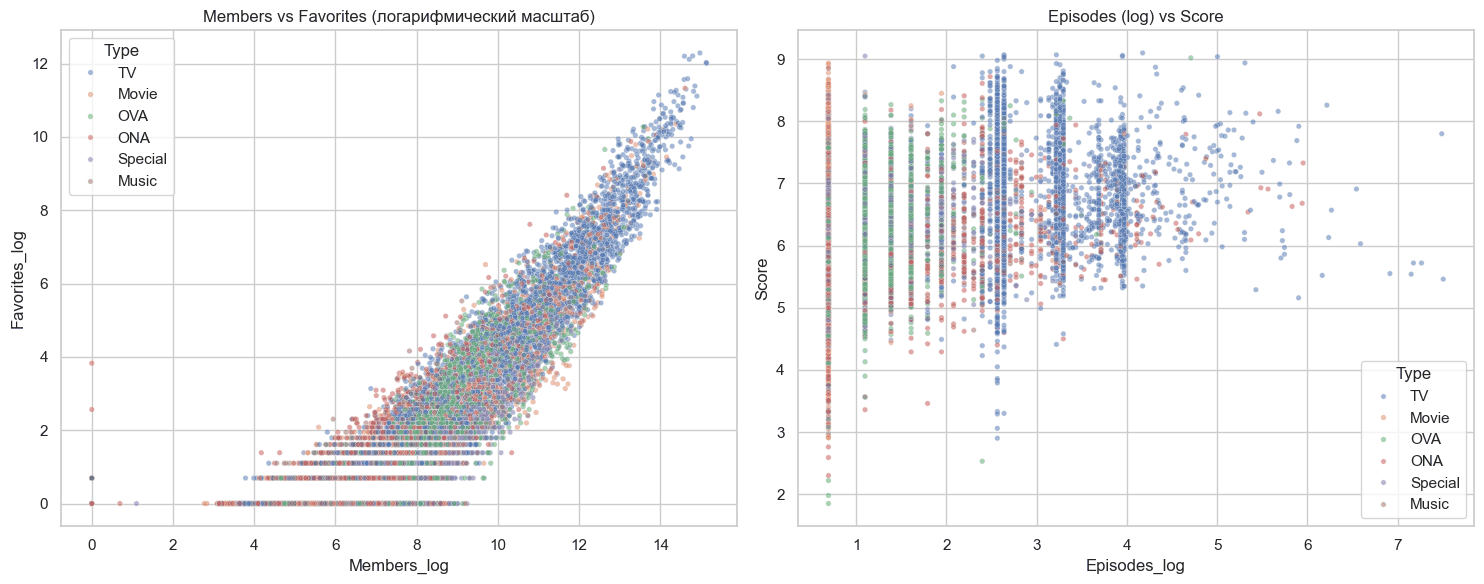

In [14]:
plot_df = df_train.copy()
for col in ['Members', 'Favorites', 'Episodes', 'Scored By']:
    plot_df[col + '_log'] = np.log1p(plot_df[col])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(data=plot_df, x='Members_log', y='Favorites_log',
                hue='Type', hue_order=order, alpha=0.5, s=15, ax=axes[0])
axes[0].set_title('Members vs Favorites (логарифмический масштаб)')

sns.scatterplot(data=plot_df, x='Episodes_log', y='Score',
                hue='Type', hue_order=order, alpha=0.5, s=15, ax=axes[1])
axes[1].set_title('Episodes (log) vs Score')

plt.tight_layout()
plt.show()

**Интерпретация.**
- Левая диаграмма: в логарифмическом масштабе число добавлений в избранное растёт вместе с числом участников почти линейно. Горизонтальные ряды точек внизу - это малые целые значения `Favorites` (0, 1, 2, ...), логарифмы которых образуют «ступеньки». Классы сильно перемешаны, то есть по этим двум признакам их разделить нельзя; в области самых больших значений (самые популярные тайтлы) преобладает `TV`.
- Единичные точки с `Members_log = 0` и ненулевым `Favorites_log` (тайтл не добавлен ни в один список, но кем-то отмечен как избранный) - вероятные неточности данных. Их единицы, поэтому оставляем.
- Правая диаграмма: вертикальные столбцы соответствуют целым значениям числа серий. В столбце с одной серией присутствуют почти все классы и весь диапазон оценок (от 2 до 9), то есть по числу серий нельзя отделить друг от друга односерийные классы (`Movie`, `Music`, `Special`, часть `OVA` и `ONA`), для них нужны другие признаки. `TV` расположен правее остальных классов.
- Оценка практически не зависит от числа серий. У самых длинных сериалов (более 150 серий) оценки преимущественно умеренные (около 5-7).

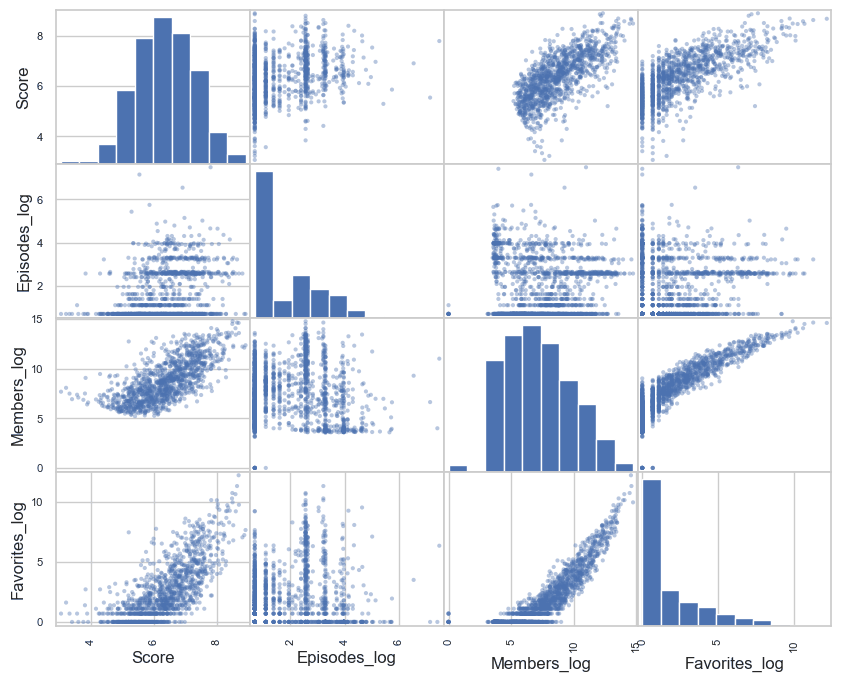

In [15]:
# Матрица диаграмм рассеяния (на подвыборке, чтобы строилась быстро)
cols_sm = ['Score', 'Episodes_log', 'Members_log', 'Favorites_log']
pd.plotting.scatter_matrix(plot_df[cols_sm].sample(2000, random_state=42),
                           figsize=(10, 8), alpha=0.4, diagonal='hist')
plt.show()

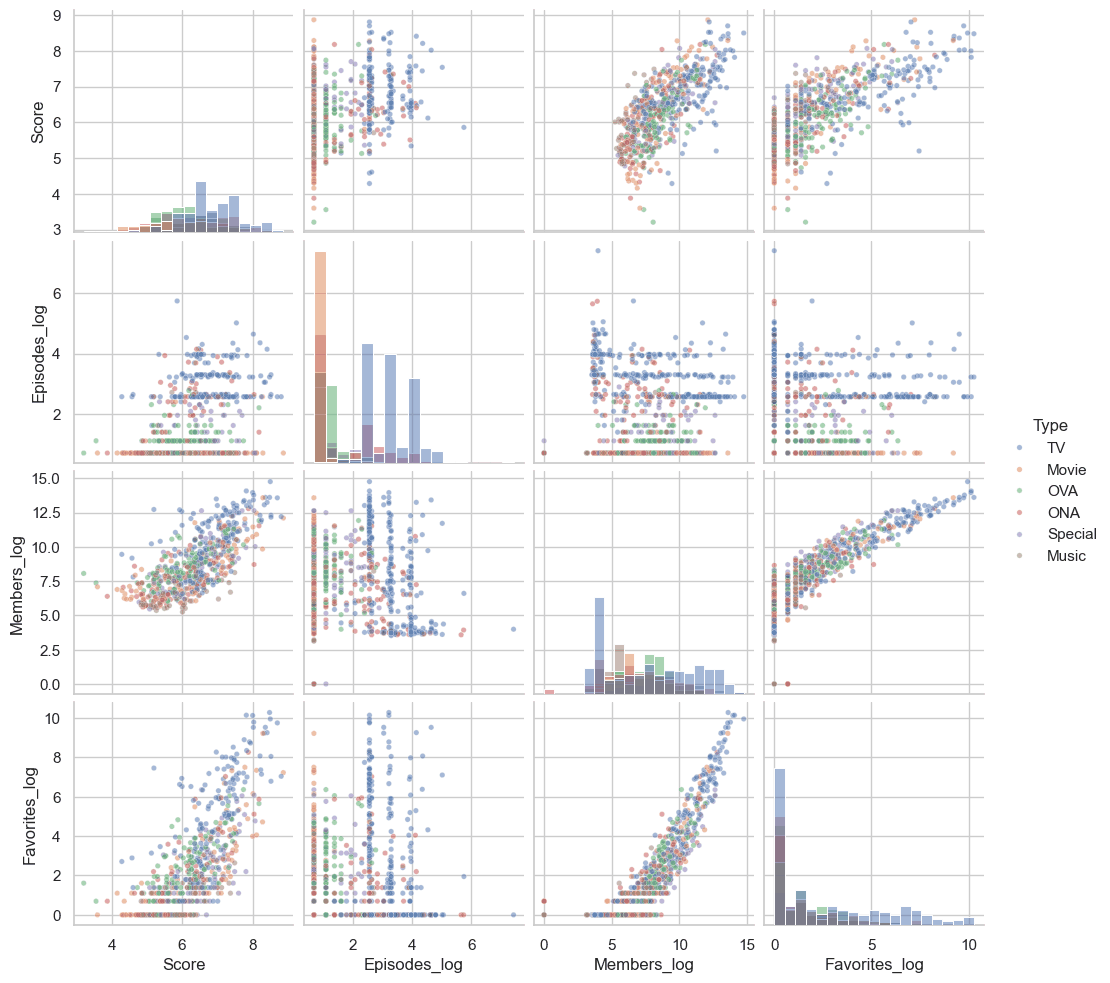

In [16]:
sns.pairplot(plot_df[['Score', 'Episodes_log', 'Members_log', 'Favorites_log', 'Type']].sample(1000, random_state=42),
             hue='Type', hue_order=order, diag_kind='hist', plot_kws={'alpha': 0.5, 's': 15})
plt.show()

**Интерпретация.** Матрица парных диаграмм подтверждает наблюдения выше; раскраска по классам даёт дополнительную информацию.
- `Score` растёт вместе с `Members_log` и `Favorites_log`. Самые высокие оценки и самая большая популярность - у `TV`; разброс оценок при этом большой.
- Лучше всего классы различает `Episodes_log`: почти все `Movie` имеют ровно одну серию, `OVA` сосредоточены на 1-3 сериях, а у `TV` несколько пиков около 12-13, 26 и 52 серий (стандартные длины сезонов). Горизонтальные полосы `TV` идут через весь диапазон `Members_log`: число серий не зависит от популярности.
- `Music` лежит в области малых `Members_log` и нулевых значений `Favorites_log`.
- Среди `TV` есть группа с большим числом серий и малым `Members_log` (около 4, то есть порядка 50 пользователей): это длинные малоизвестные сериалы.
- Гистограммы `Score` по классам сильно перекрываются: по оценке классы различаются слабо.

### 3.6 Корреляционная матрица

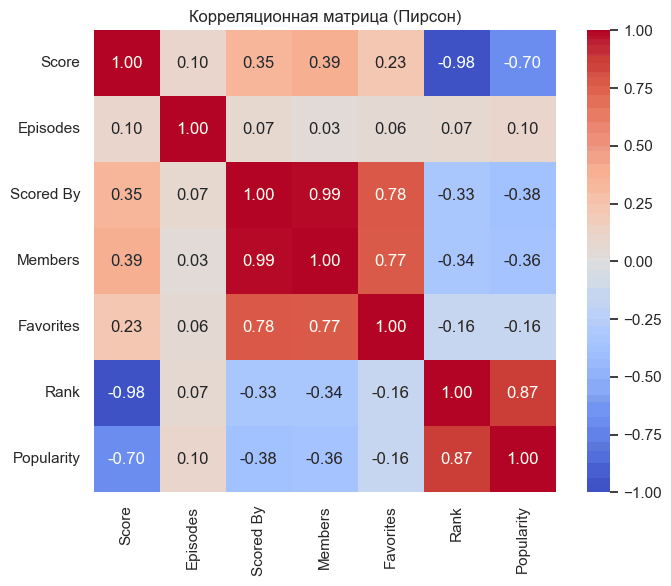

In [17]:
corr = df_train[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Корреляционная матрица (Пирсон)')
plt.show()

In [18]:
# Пары признаков с |корреляцией| > 0.5
corr.where(np.triu(np.abs(corr) > 0.5, k=1)).stack().sort_values(ascending=False)

Scored By  Members       0.988856
Rank       Popularity    0.871720
Scored By  Favorites     0.779053
Members    Favorites     0.766367
Score      Popularity   -0.695119
           Rank         -0.976139
dtype: float64

**Интерпретация.** Сильно коррелируют:
- `Scored By` и `Members` (0.99): число поставивших оценку почти пропорционально числу добавивших в список - признаки практически дублируют друг друга;
- `Score` и `Rank` (−0.98): ранг вычисляется по оценке, поэтому признаки почти функционально связаны (знак минус, так как лучший ранг - это меньшее число);
- `Rank` и `Popularity` (0.87), `Members`/`Scored By` и `Favorites` (≈0.77-0.78), `Score` и `Popularity` (−0.70).

`Episodes` почти не коррелирует с остальными признаками (|r| ≤ 0.10): он несёт независимую информацию, что согласуется с его большой ролью в различении классов. Коэффициент Пирсона измеряет только линейную связь и на данных с тяжёлыми хвостами занижает зависимость (например, `Score`-`Members` всего 0.39, хотя на диаграмме рассеяния в логарифмическом масштабе связь хорошо видна). Сильно коррелирующие признаки избыточны; вернёмся к этому в п. 12.

### 3.7 Категориальные признаки и целевая переменная
Для категориальных признаков `Source`, `Rating` и `Status` смотрим, как распределены классы внутри каждой категории. Строим доли, а не количества: так редкие категории сопоставимы с частыми.

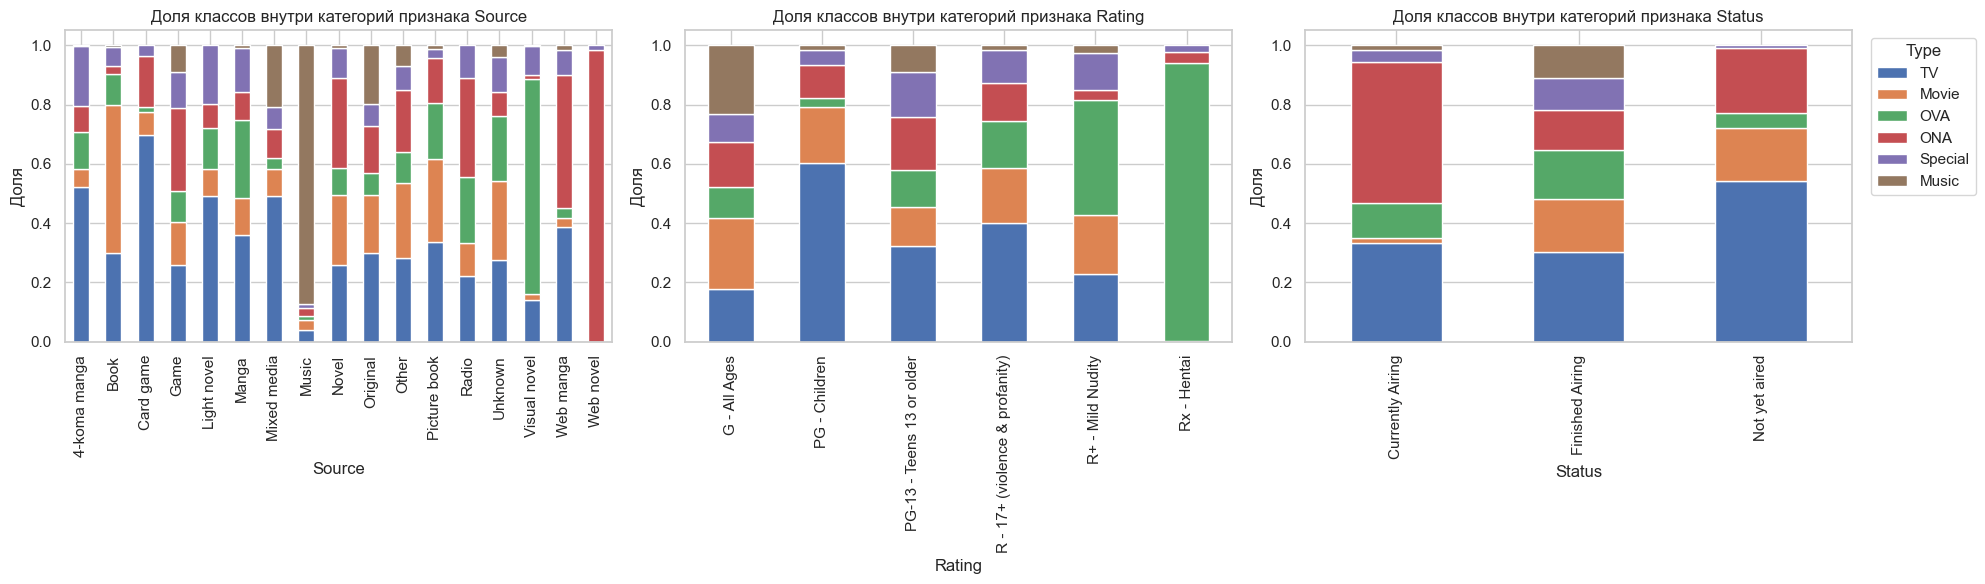

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, col in zip(axes, ['Source', 'Rating', 'Status']):
    ct = pd.crosstab(df_train[col], df_train['Type'], normalize='index')[order]
    ct.plot(kind='bar', stacked=True, ax=ax, legend=False)
    ax.set_title(f'Доля классов внутри категорий признака {col}')
    ax.set_ylabel('Доля')
axes[-1].legend(title='Type', loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

**Интерпретация.**
- `Source`: часть категорий почти однозначно определяет класс. Источник `Music` - это в основном класс `Music` (≈87%), `Web novel` - почти всегда `ONA`, `Visual novel` - преимущественно `OVA` (≈70%), `Card game` - преимущественно `TV` (≈70%), `Book` - в половине случаев `Movie`. Самая частая категория `Original` содержит смесь всех классов, поэтому сама по себе класс не определяет.
- `Rating`: `Rx - Hentai` - это почти всегда `OVA` (≈94%), `PG - Children` - в основном `TV` (≈60%), класс `Music` заметно представлен только в категории `G - All Ages` (≈23%), в `R+ - Mild Nudity` велика доля `OVA` (≈40%).
- `Status`: 97% объектов (18 056 из 18 623) имеют значение `Finished Airing`, поэтому в этой категории состав классов почти повторяет общий. Среди выходящих сейчас тайтлов велика доля `ONA` (≈47%), среди ещё не вышедших - `TV` (≈54%), `Music` и `Special` практически отсутствуют. Из-за малого числа таких объектов признак слабо влияет на предсказание.

Таким образом, `Source` и `Rating` полезны для распознавания отдельных классов, `Status` почти константен.

### Выводы по пункту 3
1. Классы умеренно несбалансированы (≈3:1), поэтому качество модели оцениваем не только по accuracy, но и по матрице рассогласования и F1-мере по классам.
2. Лучше всего классы различают число серий и длительность: `Music` и `ONA` - короткие, `Movie` - самые длинные, `TV` - десятки серий по ≈24 минуты. `TV` и `OVA` близки по длительности и различаются числом серий, а среди односерийных тайтлов классы по числу серий не отделить.
3. Популярность (`Members`, `Scored By`, `Favorites`) отделяет `Music` (наименее популярный класс) и `TV` (самый широкий разброс), но классы сильно перекрываются; `Score` различает классы слабо.
4. Из категориальных признаков `Source` и `Rating` информативны для отдельных классов (`Web novel` → `ONA`, `Rx - Hentai` → `OVA`, `PG - Children` → `TV`), `Status` почти константен.
5. Количественные признаки имеют тяжёлые хвосты и разные масштабы, поэтому для метода ближайших соседей нужны логарифмирование и стандартизация (п. 7).
6. Часть признаков избыточна (`Scored By` и `Members`, `Score` и `Rank`), это учтём в п. 12.
7. Нулевые значения `Rank` и `Popularity`, ошибки в длительности и пропуски `Score` разобраны в п. 4 и 5.

## Пункт 4: Выбросы

Необычные значения бывают двух видов:
- **невалидные значения (ошибки)** - физически невозможные или явно служебные значения (например, ранг 0); их нужно исправить или удалить;
- **выбросы** - редкие, но реальные значения (например, сериал на 1800 серий); они несут информацию о хвостах распределения, и просто выбрасывать их неправильно.

Правила проверки невалидных значений не используют статистику по данным, поэтому применяются одинаково к обучающей и тестовой выборкам. Сначала проверим подозрительные значения.

In [20]:
df_train = df_train.copy()
df_test = df_test.copy()

print('Score вне [1, 10]:    ', ((df_train['Score'] < 1) | (df_train['Score'] > 10)).sum())
print('Episodes <= 0:        ', (df_train['Episodes'] <= 0).sum())
print('Rank <= 0:            ', (df_train['Rank'] <= 0).sum())
print('Popularity <= 0:      ', (df_train['Popularity'] <= 0).sum())
print('Scored By > Members:  ', (df_train['Scored By'] > df_train['Members']).sum())

Score вне [1, 10]:     0
Episodes <= 0:         0
Rank <= 0:             123
Popularity <= 0:       123
Scored By > Members:   0


In [21]:
# Самые длинные тайтлы
df_train[df_train['Episodes'] > 500][['Name', 'Type', 'Episodes', 'Duration_min', 'Members']] \
    .sort_values('Episodes', ascending=False).head(15)

,Name,Type,Episodes,Duration_min,Members
6722,Oyako Club,TV,1818.0,5.000000,1090
2266,Doraemon (1979),TV,1787.0,11.000000,59593
19397,Daomei Xiansheng,TV,1664.0,6.000000,53
5266,Hoka Hoka Kazoku,TV,1428.0,5.000000,853
11322,Kirin Ashita no Calendar,TV,1306.0,5.000000,571
8601,Monoshiri Daigaku: Ashita no Calendar,TV,1274.0,5.000000,753
6106,Sekai Monoshiri Ryoko,TV,1006.0,5.000000,760
18887,Shuimu Baobao Kan Shijie,TV,800.0,5.000000,98
11623,Asa da yo! Kaishain,TV,744.0,0.733333,781
5876,Shima Shima Tora no Shimajirou,TV,726.0,23.000000,892


In [22]:
# Самые длинные по времени
df_train[df_train['Duration_min'] > 200][['Name', 'Type', 'Episodes', 'Duration', 'Duration_min']].head(10)

,Name,Type,Episodes,Duration,Duration_min
24448,Beyblade Burst QuadStrike,ONA,NaN,22 hr 31 min,1351.0
24734,Castlevania (Netflix animated series),TV,32.0,25 hr per ep,1500.0


In [23]:
# Квантили
df_train[['Episodes', 'Scored By', 'Members', 'Favorites', 'Duration_min']] \
    .quantile([0.005, .01, .05, .25, .5, .75, .95, .99, .995]).T

,0.005,0.010,0.050,0.250,0.500,0.750,0.950,0.990,0.995
Episodes,1.000000,1.0,1.0,1.0,2.0,13.0,52.0,144.83,237.000
Scored By,108.000000,111.0,136.0,385.0,1768.0,10751.0,135332.1,534894.46,815474.385
Members,0.000000,31.0,42.0,208.5,1059.0,9366.0,177815.2,726804.08,1048125.470
Favorites,0.000000,0.0,0.0,0.0,1.0,18.0,820.8,8909.00,18889.250
Duration_min,0.347333,0.5,1.0,4.0,17.0,25.0,86.0,110.00,119.160


**Результаты проверки.**
- У 123 объектов обучающей выборки `Rank` и `Popularity` равны 0. Ранг начинается с 1, поэтому ноль - служебная заглушка. Именно эти объекты делали первые столбцы гистограмм `Rank` и `Popularity` выше остальных.
- `Score` всегда лежит в [1, 10], `Episodes` не меньше 1, `Scored By` никогда не превышает `Members`.
- Самые длинные тайтлы (до 1818 серий) - реальные долгоиграющие сериалы (например, Doraemon, Ninja Hattori-kun, Perman), как правило с короткими сериями по 5-15 минут. Это не ошибки.
- Длительность больше 200 минут только у двух объектов. У «Castlevania» указано 25 часов на серию - очевидная ошибка ввода (вместо минут). У «Beyblade Burst QuadStrike» указано 22 ч 31 мин: по всей видимости, это суммарная длительность всех серий, а не одной. Оба значения невалидны.
- По квантилям 99% значений `Episodes` не превышают ≈145 серий (максимум 1818), у `Members` 99.5% значений не превышают ≈1.05 млн, у `Duration_min` - 119 минут. Хвосты очень тяжёлые, но реальные.

**Решения.**
1. Невалидные значения (ранг ≤ 0, `Score` вне [1, 10], `Episodes` ≤ 0, `Duration_min` > 300) заменяем на `NaN` и обрабатываем в п. 5. Строки не удаляем: остальные признаки у этих объектов корректны.
2. Выбросы-хвосты **не удаляем**. Правило Тьюки ($Q_1 - 1.5\,IQR$, $Q_3 + 1.5\,IQR$) здесь вредно: оно отсекло бы как раз длинные сериалы, то есть значения, характерные для класса `TV`, и мы потеряли бы информацию, нужную для классификации.
3. Влияние хвостов на метод ближайших соседей снизим не удалением, а логарифмированием и стандартизацией (п. 7).

In [24]:
def fix_invalid(d):
    d = d.copy()
    for col in ['Rank', 'Popularity']:
        d.loc[d[col] <= 0, col] = np.nan        # 0 - заглушка, а не настоящий ранг
    d.loc[(d['Score'] < 1) | (d['Score'] > 10), 'Score'] = np.nan
    d.loc[d['Episodes'] <= 0, 'Episodes'] = np.nan
    d.loc[d['Duration_min'] > 300, 'Duration_min'] = np.nan   # ошибки ввода длительности
    return d

df_train = fix_invalid(df_train)
df_test = fix_invalid(df_test)
print('Готово.')

Готово.


## Пункт 5: Обработка пропущенных значений

**Отбор признаков.** Не используем:
- `anime_id`, `Name`, `English name`, `Other name`, `Image URL` - идентификаторы и названия, предсказательной информации не несут;
- `Synopsis` - свободный текст, k-NN с ним напрямую работать не может;
- `Producers`, `Licensors`, `Studios`, `Premiered` - много уникальных значений и 43-81% пропусков;
- `Aired`, `Duration` - сырые текстовые даты и длительность (длительность заменена числом `Duration_min`).

Оставляем: числовые `Score`, `Episodes`, `Scored By`, `Members`, `Favorites`, `Rank`, `Popularity`, `Duration_min`, категориальные `Source`, `Rating`, `Status` и жанры `Genres` (разберём в п. 6).

In [25]:
num_cols = ['Score', 'Episodes', 'Scored By', 'Members', 'Favorites', 'Rank', 'Popularity', 'Duration_min']
cat_cols = ['Source', 'Rating', 'Status']
features = num_cols + cat_cols + ['Genres']

X_train, y_train = df_train[features].copy(), df_train['Type']
X_test,  y_test  = df_test[features].copy(),  df_test['Type']

miss = pd.DataFrame({'train, %': X_train.isna().mean() * 100,
                     'test, %':  X_test.isna().mean() * 100}).round(2)
miss[miss['train, %'] > 0].sort_values('train, %', ascending=False)

,"train, %","test, %"
Score,36.95,36.39
Scored By,36.95,36.39
Genres,19.71,20.04
Rank,18.93,19.35
Rating,2.45,2.50
Duration_min,2.45,2.21
Episodes,2.17,2.24
Popularity,0.66,0.74


In [26]:
# Как устроены пропуски в Score
print('Пропуски Score и Scored By совпадают:', (X_train['Score'].isna() == X_train['Scored By'].isna()).mean())
print('Минимум Scored By:', X_train['Scored By'].min())
print('Доля пропусков Score по классам, %:')
df_train.groupby('Type')['Score'].apply(lambda s: s.isna().mean() * 100).round(1)

Пропуски Score и Scored By совпадают: 1.0
Минимум Scored By: 100.0
Доля пропусков Score по классам, %:


Type
Movie      43.7
Music      44.3
ONA        45.9
OVA        19.7
Special    19.6
TV         41.4
Name: Score, dtype: float64

**Анализ пропусков.** Больше всего пропусков у `Score` и `Scored By` (≈37%), причём они совпадают у всех объектов. Минимальное значение `Scored By` среди заполненных равно 100: оценка есть только у тайтлов, которые оценили не менее 100 пользователей. Значит, пропуск **не случаен**: он означает «тайтл малоизвестен». Доля пропусков заметно зависит от класса: у `OVA` и `Special` она около 20%, у `Movie`, `Music`, `ONA`, `TV` - 41-46%. Поэтому сам факт пропуска несёт информацию о классе.

**Стратегия.** Все параметры считаем только по обучающей выборке и применяем к тестовой:
- числовые признаки - заполнение **медианой** (устойчива к выбросам, а хвосты у нас тяжёлые);
- категориальный `Rating` - **самым частым значением**;
- `Genres` - отдельное значение `'Unknown'`;
- для `Score` и `Rank` добавляем **индикаторы пропуска** (`Score_missing`, `Rank_missing`), чтобы сохранить информацию о самом факте пропуска. Для `Scored By` отдельный индикатор не нужен: он совпал бы с `Score_missing`.

Удаление строк не подходит: пропуски есть у трети объектов, а малоизвестные тайтлы - как раз то, что нужно уметь классифицировать.

In [27]:
from sklearn.impute import SimpleImputer

# 1. Индикаторы пропусков (до заполнения)
for col in ['Score', 'Rank']:
    X_train[col + '_missing'] = X_train[col].isna().astype(int)
    X_test[col + '_missing']  = X_test[col].isna().astype(int)

# 2. Числовые - медиана (fit только на train)
imp_num = SimpleImputer(strategy='median')
imp_num.fit(X_train[num_cols])
X_train[num_cols] = imp_num.transform(X_train[num_cols])
X_test[num_cols]  = imp_num.transform(X_test[num_cols])

# 3. Категориальные - самое частое значение (fit только на train)
imp_cat = SimpleImputer(strategy='most_frequent')
imp_cat.fit(X_train[cat_cols])
X_train[cat_cols] = imp_cat.transform(X_train[cat_cols])
X_test[cat_cols]  = imp_cat.transform(X_test[cat_cols])

# 4. Жанры
X_train['Genres'] = X_train['Genres'].fillna('Unknown')
X_test['Genres']  = X_test['Genres'].fillna('Unknown')

print('Пропусков в train:', X_train.isna().sum().sum())
print('Пропусков в test: ', X_test.isna().sum().sum())

Пропусков в train: 0
Пропусков в test:  0


## Пункт 6: Обработка категориальных признаков

Алгоритмы из библиотеки `scikit-learn` не умеют работать со строками, поэтому категориальные признаки нужно закодировать числами. Простая нумерация категорий (1, 2, 3, ...) не подходит: метод ближайших соседей считает расстояния, и он решил бы, что категории «близки» или «далеки» в зависимости от случайного номера. Поэтому используем бинаризацию (one-hot encoding): каждое значение признака становится отдельным столбцом из 0 и 1.

Признаки `Source`, `Rating` и `Status` - номинальные. Признак `Genres` содержит несколько жанров через запятую, поэтому для него создаём отдельный бинарный столбец на каждый жанр (объект может иметь несколько жанров одновременно). Значение `'Unknown'`, которым заполнены пропуски, становится ещё одним таким столбцом.

In [28]:
from sklearn.preprocessing import OneHotEncoder

# Число категорий и самые частые значения
for col in cat_cols:
    print(col, '-', X_train[col].nunique(), 'значений')
    print(X_train[col].value_counts().head(6), '\n')

Source - 17 значений
Source
Original        7197
Manga           3507
Unknown         2780
Game             923
Visual novel     813
Other            746
Name: count, dtype: int64 

Rating - 6 значений
Rating
PG-13 - Teens 13 or older         6813
G - All Ages                      5738
PG - Children                     3069
Rx - Hentai                       1090
R - 17+ (violence & profanity)    1065
R+ - Mild Nudity                   848
Name: count, dtype: int64 

Status - 3 значений
Status
Finished Airing     18056
Not yet aired         315
Currently Airing      252
Name: count, dtype: int64 



**Результаты.** Число категорий: `Source` - 17, `Rating` - 6, `Status` - 3. Самая частая категория `Source` - `Original` (7197 объектов), далее `Manga` (3507) и `Unknown` (2780). Значение `Unknown` («источник не указан») не заменяем: это отдельная категория, и сам факт неуказанного источника может быть информативным. Признак `Status` почти константен: 18 056 из 18 623 объектов (≈97%) имеют значение `Finished Airing`.

### 6.1 Source, Rating, Status
Кодировщик обучается на обучающей выборке. Параметр `handle_unknown='ignore'` нужен на случай, если в тестовой выборке встретится категория, которой не было в обучающей: тогда все её столбцы будут равны 0.

In [29]:
enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
enc.fit(X_train[cat_cols])

def encode_cat(X):
    dummies = pd.DataFrame(enc.transform(X[cat_cols]),
                           columns=enc.get_feature_names_out(cat_cols),
                           index=X.index)
    return pd.concat((X.drop(columns=cat_cols), dummies), axis=1)

X_train = encode_cat(X_train)
X_test = encode_cat(X_test)
X_train.shape

(18623, 37)

Вместо трёх столбцов получили 17 + 6 + 3 = 26 бинарных столбцов. Всего в таблице стало 37 столбцов: 8 количественных, 2 индикатора пропусков, 26 бинарных и столбец `Genres`, который обрабатывается ниже.

### 6.2 Genres
Оставляем только жанры, которые встречаются не менее чем у 1% объектов обучающей выборки: более редкие жанры давали бы почти пустые столбцы и только увеличили бы размерность.

In [30]:
genre_dummies = X_train['Genres'].str.get_dummies(sep=', ')
genre_freq = genre_dummies.mean().sort_values(ascending=False)
top_genres = genre_freq[genre_freq >= 0.01].index.tolist()

print('Всего жанров в обучающей выборке:', genre_dummies.shape[1])
print('Оставляем:', len(top_genres))
genre_freq.head(10)

Всего жанров в обучающей выборке: 22
Оставляем: 17


Comedy           0.288568
Fantasy          0.213499
Unknown          0.197068
Action           0.191108
Adventure        0.154111
Sci-Fi           0.125060
Drama            0.113516
Romance          0.083767
Slice of Life    0.069484
Supernatural     0.059711
dtype: float64

In [31]:
def encode_genres(X):
    g = X['Genres'].str.get_dummies(sep=', ')
    g = g.reindex(columns=top_genres, fill_value=0).add_prefix('Genre_')
    return pd.concat((X.drop(columns='Genres'), g), axis=1)

X_train = encode_genres(X_train)
X_test = encode_genres(X_test)

print(X_train.shape, X_test.shape)
print('Пропусков:', X_train.isna().sum().sum(), X_test.isna().sum().sum())
X_train.head()

(18623, 53) (6208, 53)
Пропусков: 0 0


,Score,Episodes,Scored By,Members,Favorites,Rank,Popularity,Duration_min,Score_missing,Rank_missing,Source_4-koma manga,Source_Book,Source_Card game,Source_Game,Source_Light novel,...,Genre_Unknown,Genre_Action,Genre_Adventure,Genre_Sci-Fi,Genre_Drama,Genre_Romance,Genre_Slice of Life,Genre_Supernatural,Genre_Hentai,Genre_Mystery,Genre_Avant Garde,Genre_Sports,Genre_Ecchi,Genre_Horror,Genre_Award Winning
24404,6.39,2.0,1768.0,2107.0,9.0,10074.5,10528.0,17.0,1,1,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0
22628,6.39,1.0,1768.0,75.0,0.0,14430.0,21276.0,25.0,1,0,0.0,0.0,0.0,0.0,0.0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4122,6.43,3.0,1907.0,5704.0,17.0,10074.5,7569.0,29.0,0,1,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0
24572,6.39,1.0,1768.0,0.0,0.0,10074.5,12365.0,1.0,1,1,0.0,0.0,0.0,1.0,0.0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8574,6.32,3.0,3119.0,8015.0,23.0,10074.5,6638.0,20.0,0,1,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0


В обучающей выборке встречается 22 значения жанров, оставлено 17 - те, что есть не менее чем у 1% объектов. Самые частые: `Comedy` (≈28.9%), `Fantasy` (≈21.3%), `Action` (≈19.1%), `Adventure` (≈15.4%). Доля значения `Unknown` (≈19.7%) совпадает с долей пропусков в `Genres`, поэтому оно стало отдельным бинарным признаком. После кодирования таблица содержит 53 признака (8 количественных, 2 индикатора пропусков, 26 бинарных столбцов для `Source`, `Rating`, `Status` и 17 для жанров) и не содержит пропусков ни в обучающей, ни в тестовой выборке.

## Пункт 7: Нормализация

Метод ближайших соседей определяет близость объектов по евклидову расстоянию, поэтому признаки с большим масштабом доминируют над остальными. У нас масштабы различаются на порядки: `Members` достигает миллионов, `Popularity` и `Rank` - десятков тысяч, а `Score` лежит в пределах от 1 до 10. Без нормализации расстояние определялось бы почти только признаками с самыми большими значениями (Members, Scored By, Rank, Popularity), а Score и бинарные признаки почти не влияли бы на него.

Делаем в два шага:
1. **Логарифмирование** $\log(1+x)$ признаков с тяжёлым хвостом (`Episodes`, `Scored By`, `Members`, `Favorites`, `Duration_min`), как в п. 3. Иначе несколько тайтлов с огромными значениями растянули бы шкалу, а основная масса объектов оказалась бы сжата около нуля.
2. **Стандартизация** всех количественных признаков (нулевое среднее и единичное стандартное отклонение). Параметры вычисляются только по обучающей выборке и затем применяются к тестовой.

Бинарные столбцы (результат one-hot кодирования и индикаторы пропусков) уже принимают значения 0 и 1, поэтому их не стандартизуем: у редких категорий стандартное отклонение мало, и после стандартизации единица превратилась бы в очень большое число, которое доминировало бы в расстоянии.

In [32]:
log_cols = ['Episodes', 'Scored By', 'Members', 'Favorites', 'Duration_min']
for X in (X_train, X_test):
    X[log_cols] = np.log1p(X[log_cols])

In [33]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train[num_cols])

X_train[num_cols] = scaler.transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

X_train[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Score,18623.0,0.0,1.0,-6.16,-0.33,0.01,0.35,3.69
Episodes,18623.0,0.0,1.0,-0.84,-0.84,-0.52,0.70,4.56
Scored By,18623.0,-0.0,1.0,-1.76,-0.49,-0.11,0.26,4.10
Members,18623.0,0.0,1.0,-2.78,-0.75,-0.13,0.69,2.97
Favorites,18623.0,-0.0,1.0,-0.77,-0.77,-0.47,0.51,4.57
Rank,18623.0,0.0,1.0,-1.92,-0.74,-0.00,0.74,1.91
Popularity,18623.0,0.0,1.0,-1.74,-0.87,-0.00,0.86,1.73
Duration_min,18623.0,-0.0,1.0,-2.38,-0.79,0.25,0.59,2.35


**Результат.** У всех восьми количественных признаков среднее равно 0, а стандартное отклонение равно 1. Минимумы `Episodes` (−0.84) и `Favorites` (−0.77) совпадают с 25%-квантилями: не менее четверти объектов имеют ровно одну серию, а `Favorites` у многих равен нулю. Большой отрицательный минимум `Score` (−6.16) объясняется тем, что у 37% объектов оценка заменена медианой: разброс получился небольшим, и редкие очень низкие оценки (около 2) после стандартизации удалены от среднего. `Rank` и `Popularity` не логарифмировали: это порядковые номера с равномерным распределением, хвостов у них нет. Бинарные столбцы оставлены без изменений, их масштаб (0 и 1) сопоставим с масштабом стандартизованных признаков. Данные готовы к обучению модели.

## Пункт 8: Выбор классификатора и запуск

Для решения задачи используем метод $k$ ближайших соседей ($k$ NN). Обоснование выбора:
- метод не делает предположений о форме распределения классов и вида границ между ними; по результатам п. 3 классы перекрываются сложным образом, поэтому гибкий непараметрический метод подходит;
- у метода один основной гиперпараметр - число соседей $k$, поэтому легко изучить, как ошибка зависит от сложности модели;
- метод основан на расстояниях, а данные в п. 5-7 как раз подготовлены для этого (заполнены пропуски, закодированы категории, выполнена стандартизация);
- обучающая выборка среднего размера (18 623 объекта), поэтому предсказание выполняется быстро;
- результат служит базовой моделью, с которой в п. 10 сравним другие методы.

Ограничения метода: он чувствителен к лишним и коррелированным признакам (у нас 53 признака, см. п. 12) и при несбалансированных классах склонен отдавать предпочтение частым классам.

Сначала запускаем классификатор с числом соседей по умолчанию ($k = 5$).

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_train_predict = knn.predict(X_train)
y_test_predict = knn.predict(X_test)

Используется евклидова метрика (по умолчанию) и равные веса всех соседей: класс объекта определяется голосованием $k$ ближайших объектов обучающей выборки. Ошибки модели и подбор $k$ рассмотрены в п. 9.

## Пункт 9: Ошибки, матрицы рассогласования, выбор $k$

Ошибка классификации - доля неверно предсказанных объектов: $\text{err} = 1 - \text{accuracy}$. Вычисляем её на обучающей и тестовой выборках и сводим результаты в таблицу.

In [35]:
err_train = np.mean(y_train != y_train_predict)
err_test = np.mean(y_test != y_test_predict)

err_table = pd.DataFrame(columns=('train', 'test'))
err_table.loc['kNN, k=5', :] = (err_train, err_test)
err_table

,train,test
"kNN, k=5",0.156742,0.226965


### 9.1 Матрицы рассогласования
В матрице рассогласования строки соответствуют истинным классам, столбцы - предсказанным. На диагонали находятся правильно классифицированные объекты, вне диагонали - ошибки.

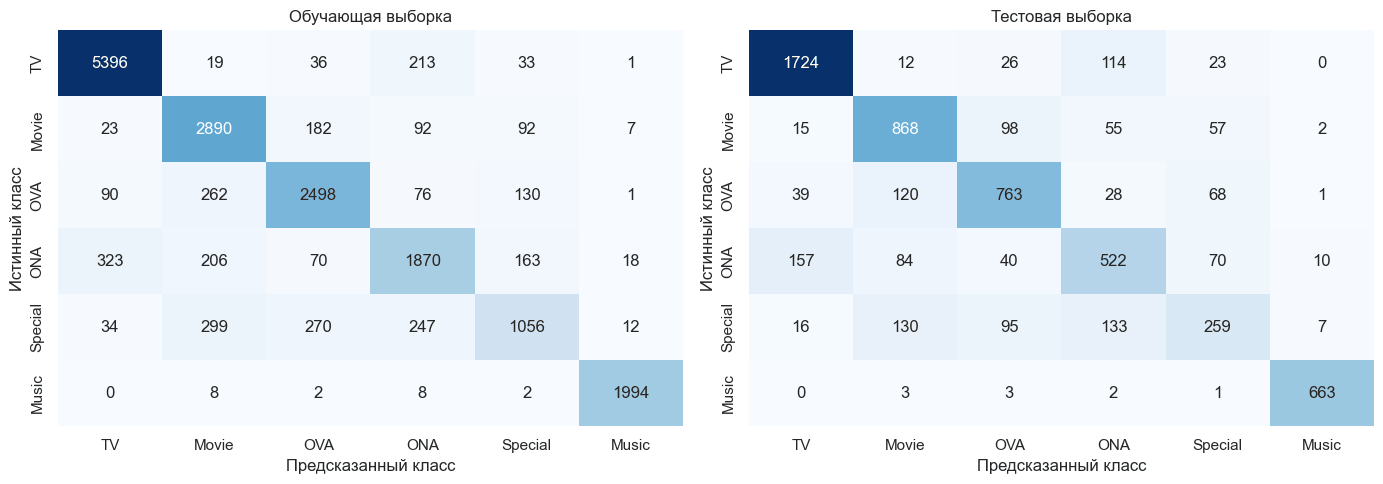

In [36]:
from sklearn.metrics import confusion_matrix, classification_report

labels = ['TV', 'Movie', 'OVA', 'ONA', 'Special', 'Music']

def plot_cm(y_true, y_pred, title, ax):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_cm(y_train, y_train_predict, 'Обучающая выборка', axes[0])
plot_cm(y_test, y_test_predict, 'Тестовая выборка', axes[1])
plt.tight_layout()
plt.show()

In [37]:
# Матрица рассогласования на тестовой выборке в виде таблицы
pd.DataFrame(confusion_matrix(y_test, y_test_predict, labels=labels),
             index=labels, columns=labels)

,TV,Movie,OVA,ONA,Special,Music
TV,1724,12,26,114,23,0
Movie,15,868,98,55,57,2
OVA,39,120,763,28,68,1
ONA,157,84,40,522,70,10
Special,16,130,95,133,259,7
Music,0,3,3,2,1,663


In [38]:
# Точность, полнота и F1-мера по классам (тестовая выборка)
print(classification_report(y_test, y_test_predict, labels=labels, digits=3))

              precision    recall  f1-score   support

          TV      0.884     0.908     0.896      1899
       Movie      0.713     0.793     0.751      1095
         OVA      0.744     0.749     0.747      1019
         ONA      0.611     0.591     0.601       883
     Special      0.542     0.405     0.463       640
       Music      0.971     0.987     0.979       672

    accuracy                          0.773      6208
   macro avg      0.744     0.739     0.739      6208
weighted avg      0.766     0.773     0.768      6208



При $k = 5$ ошибка на обучающей выборке равна 0.157, на тестовой - 0.227 (accuracy 0.773). Классификатор, всегда отвечающий `TV`, ошибался бы примерно в 69% случаев (accuracy ≈ 0.306, см. п. 3), то есть модель заметно лучше тривиальной. Разрыв между обучением и тестом (≈7 п.п.) говорит об умеренном переобучении: метод запоминает обучающие объекты и на новых работает хуже.

По матрице рассогласования и отчёту по классам:
- `Music` распознаётся почти безупречно (663 из 672, полнота 0.987, F1 = 0.979): клипы очень короткие и малопопулярные (п. 3).
- `TV` распознаётся хорошо (1724 из 1899, F1 = 0.896). Главная путаница - с `ONA`: 114 сериалов `TV` предсказаны как `ONA`, а 157 объектов `ONA` - как `TV`. Оба класса часто многосерийные, их признаки похожи.
- `Movie` и `OVA` часто путаются друг с другом (98 фильмов предсказано как `OVA`, 120 `OVA` - как `Movie`): у обоих классов мало серий (чаще всего одна), а длительность частично перекрывается (п. 3).
- `Special` - самый трудный класс (полнота 0.405, F1 = 0.463): верно найдено лишь 259 из 640, остальные «рассыпаются» по `Movie` (130), `ONA` (133) и `OVA` (95). У этого класса нет собственных характерных значений признаков, он похож на все остальные короткие форматы. Кроме того, это самый малочисленный класс (≈10%), и среди соседей чаще оказываются объекты более крупных классов.
- `ONA` распознаётся хуже среднего (F1 = 0.601), в основном из-за путаницы с `TV`.

### 9.2 Подбор числа соседей
Число соседей $k$ подбираем перекрёстной проверкой (5 блоков со стратификацией) на обучающей выборке: для каждого $k$ модель обучается на четырёх блоках и проверяется на пятом, результаты усредняются. Тестовая выборка при подборе не используется. Качество измеряем долей верных ответов (accuracy), ошибка равна $1 - \text{accuracy}$.

Предобработка (медианы, параметры стандартизации) вычислена по всей обучающей выборке, поэтому статистики проверочных блоков косвенно в неё попадают; для медиан и средних влияние пренебрежимо мало.

In [39]:
from sklearn.model_selection import GridSearchCV

k_arr = np.array([1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 40, 50])
params = {'n_neighbors': k_arr}

grid = GridSearchCV(KNeighborsClassifier(), params, scoring='accuracy',
                    cv=5, return_train_score=True)
grid.fit(X_train, y_train)

grid.best_score_, grid.best_params_

(np.float64(0.7751709138618358), {'n_neighbors': np.int64(7)})

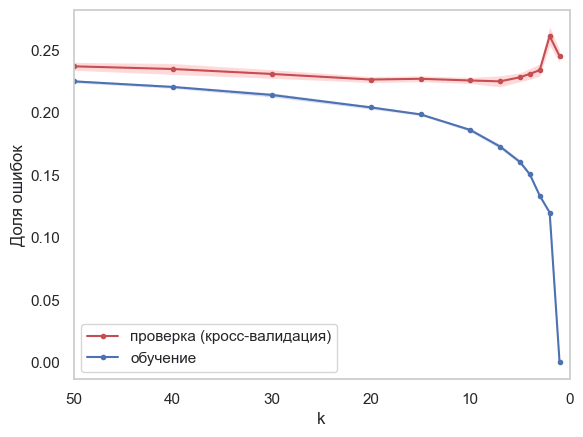

In [40]:
err_cv = 1 - grid.cv_results_['mean_test_score']
std_cv = grid.cv_results_['std_test_score']
err_tr = 1 - grid.cv_results_['mean_train_score']
std_tr = grid.cv_results_['std_train_score']

plt.plot(k_arr, err_cv, 'r.-', label='проверка (кросс-валидация)')
plt.plot(k_arr, err_tr, 'b.-', label='обучение')
plt.fill_between(k_arr, err_cv - std_cv, err_cv + std_cv, alpha=0.15, facecolor='red')
plt.fill_between(k_arr, err_tr - std_tr, err_tr + std_tr, alpha=0.15, facecolor='blue')
plt.xlim([max(k_arr), 0])
plt.grid()
plt.xlabel('k')
plt.ylabel('Доля ошибок')
plt.legend()
plt.show()

Ось $k$ направлена справа налево: слева - простая модель (большое $k$, сглаженная граница), справа - сложная (малое $k$, граница подстраивается под отдельные объекты). Ошибка на обучающей выборке монотонно растёт с ростом $k$: при $k = 1$ она равна нулю (каждый объект - свой собственный ближайший сосед), при $k = 50$ приближается к ошибке проверки. Ошибка на проверочных блоках ведёт себя иначе: при малых $k$ она велика (≈0.26 при $k = 2$) - модель переобучена и подстраивается под шум. Минимум достигается при $k = 7$ (≈0.225, accuracy ≈ 0.775). При $k$ от 7 до 20 ошибка почти не меняется (≈0.225-0.228), а при дальнейшем росте медленно увеличивается: модель становится слишком «сглаженной». Различия между соседними значениями $k$ в области минимума сопоставимы с разбросом ошибки между блоками (закрашенная область), поэтому любое $k$ из диапазона 7-20 практически равноценно; берём минимум, $k = 7$.

Обучаем модель с найденным оптимальным значением $k$ и вычисляем ошибки.

In [41]:
best_k = grid.best_params_['n_neighbors']

knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)

y_train_predict = knn.predict(X_train)
y_test_predict = knn.predict(X_test)

err_train = np.mean(y_train != y_train_predict)
err_test = np.mean(y_test != y_test_predict)
err_table.loc[f'kNN, k={best_k} (оптимальное)', :] = (err_train, err_test)
err_table

,train,test
"kNN, k=5",0.156742,0.226965
"kNN, k=7 (оптимальное)",0.171079,0.227126


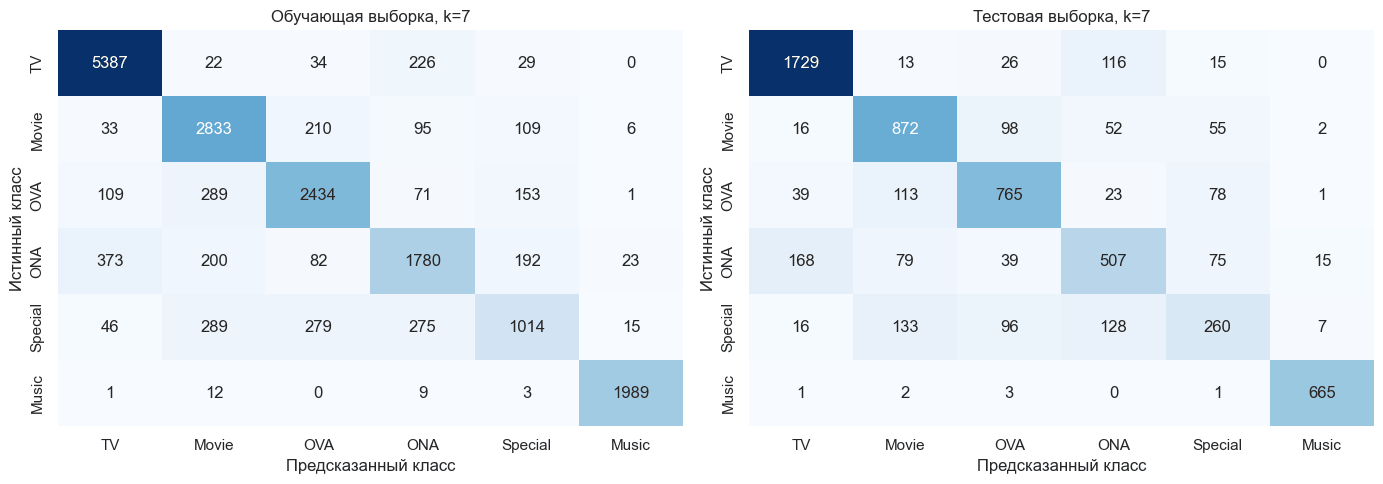

              precision    recall  f1-score   support

          TV      0.878     0.910     0.894      1899
       Movie      0.719     0.796     0.756      1095
         OVA      0.745     0.751     0.748      1019
         ONA      0.614     0.574     0.593       883
     Special      0.537     0.406     0.463       640
       Music      0.964     0.990     0.977       672

    accuracy                          0.773      6208
   macro avg      0.743     0.738     0.738      6208
weighted avg      0.765     0.773     0.767      6208



In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_cm(y_train, y_train_predict, f'Обучающая выборка, k={best_k}', axes[0])
plot_cm(y_test, y_test_predict, f'Тестовая выборка, k={best_k}', axes[1])
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_test_predict, labels=labels, digits=3))

При оптимальном $k = 7$ ошибка на обучающей выборке выросла до 0.171 (при $k = 5$ - 0.157), а на тестовой практически не изменилась: 0.2271 против 0.2270, то есть разница составляет один объект из 6208. Подбор $k$ уменьшил разрыв между обучением и тестом (с 7.0 до 5.6 п.п.), то есть сделал модель менее склонной к запоминанию, но качество на новых данных не улучшил: уже при $k = 5$ модель находилась на плоском участке кривой. Точность на тестовой выборке (0.773) совпадает с оценкой по кросс-валидации (0.775), что говорит об устойчивости результата.

Матрица рассогласования при $k = 7$ почти не отличается от матрицы при $k = 5$: те же главные ошибки - `Special` (F1 = 0.463), `ONA` (F1 = 0.593), взаимная путаница `TV`-`ONA` и `Movie`-`OVA`; лучше всего распознаются `Music` (F1 = 0.977) и `TV` (F1 = 0.894). Ошибки сосредоточены в классах, признаки которых перекрываются, поэтому одним выбором $k$ их не исправить: попробуем другие методы (п. 10) и учтём несбалансированность классов (п. 11).

## Пункт 10: Другие классификаторы

Для сравнения с $k$ NN обучим ещё несколько стандартных методов на тех же данных (те же признаки и та же предобработка):
- **логистическая регрессия** - простой линейный метод, показывает, насколько классы разделимы линейно;
- **случайный лес** (Random Forest) - ансамбль деревьев решений; хорошо работает с признаками разной природы и позволяет оценить важность признаков;
- **градиентный бустинг** - ансамбль деревьев, которые строятся последовательно, и каждое исправляет ошибки предыдущих;
- **полносвязная нейронная сеть** (многослойный перцептрон).

Качество сравниваем по ошибке на обучающей и тестовой выборках, а также по макро-усреднённой F1-мере на тестовой выборке (среднее F1 по классам; в отличие от accuracy она не позволяет скрыть плохое качество на малочисленных классах).

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score

results = pd.DataFrame(columns=('train error', 'test error', 'test F1 (macro)'))

def evaluate(name, model, X_fit=None, y_fit=None):
    """Обучает модель и записывает ошибки в таблицу results"""
    if X_fit is None:
        X_fit, y_fit = X_train, y_train
    model.fit(X_fit, y_fit)
    p_train = model.predict(X_train)
    p_test = model.predict(X_test)
    results.loc[name, :] = (np.mean(y_train != p_train),
                            np.mean(y_test != p_test),
                            f1_score(y_test, p_test, average='macro'))
    return model

evaluate('kNN, k=7', KNeighborsClassifier(n_neighbors=7))
evaluate('Logistic Regression', LogisticRegression(max_iter=1000))
rf = evaluate('Random Forest', RandomForestClassifier(n_estimators=200, random_state=42))
evaluate('Gradient Boosting', GradientBoostingClassifier(random_state=42))
evaluate('Neural Network', MLPClassifier(hidden_layer_sizes=(20, 10), max_iter=500, random_state=42))

results.round(3)

,train error,test error,test F1 (macro)
"kNN, k=7",0.171079,0.227126,0.738372
Logistic Regression,0.23283,0.228093,0.738502
Random Forest,0.000107,0.181379,0.790056
Gradient Boosting,0.170488,0.191849,0.780173
Neural Network,0.170649,0.201675,0.770778


Результаты сведены в таблицу (ошибка на обучающей и тестовой выборках, макро-F1 на тестовой).
- **Логистическая регрессия** даёт ошибки на обучающей и тестовой выборках почти одинаковые (0.233 и 0.228), то есть недообучена: линейная граница не может разделить перекрывающиеся классы. По качеству на тесте (ошибка 0.228, F1 = 0.739) она совпадает с $k$ NN.
- **Случайный лес** лучший по обеим метрикам: ошибка на тесте 0.181 (accuracy 0.819), макро-F1 = 0.790. На обучающей выборке ошибка почти нулевая (0.0001, то есть 2 объекта из 18 623): деревья без ограничения глубины запоминают обучающие данные, но на новых объектах всё равно работают лучше остальных методов.
- **Градиентный бустинг** (ошибка 0.192, F1 = 0.780) и **нейронная сеть** (0.202, F1 = 0.771) занимают промежуточное положение: на обучающей выборке ошибка около 0.17, как у $k$ NN, но на тесте разрыв меньше, чем у $k$ NN.
- $k$ NN (ошибка 0.227, F1 = 0.738) уступает всем нелинейным ансамблям и нейронной сети. Деревья естественно отбирают информативные признаки, а $k$ NN учитывает все 53 признака с равным весом, включая малоинформативные (например, Status, редкие жанры).

Размер тестовой выборки (6208 объектов) означает, что стандартная ошибка доли верных ответов составляет около 0.5 п.п., поэтому разницу в десятые доли процента нельзя считать значимой, а разница между случайным лесом и $k$ NN (≈4.6 п.п.) значима. Гиперпараметры методов, кроме $k$ NN, не подбирались, поэтому сравнение ориентировочное.

Метод Random Forest позволяет получить оценки важности признаков. Чем значение больше, тем признак важнее.

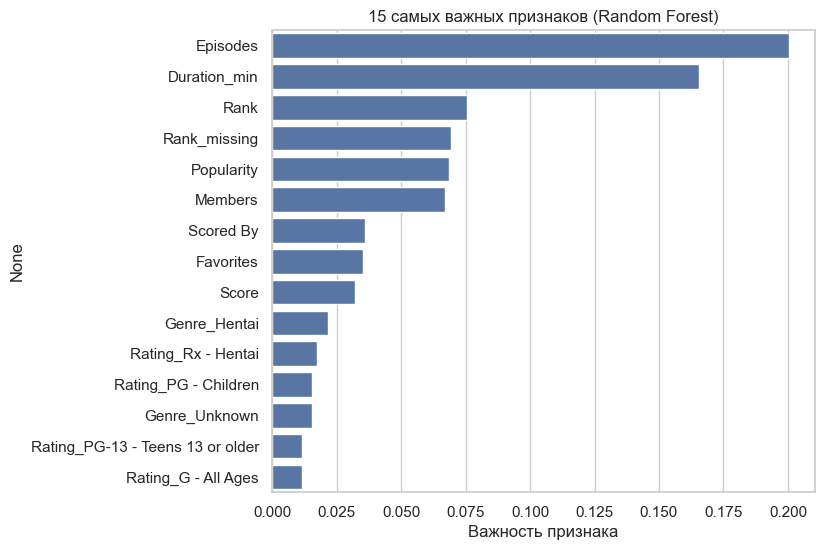

In [44]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(7, 6))
sns.barplot(y=importances.index[:15], x=importances.values[:15], orient='h')
plt.xlabel('Важность признака')
plt.title('15 самых важных признаков (Random Forest)')
plt.show()

Самые важные признаки - число серий (`Episodes`, ≈0.20) и длительность (`Duration_min`, ≈0.17): это согласуется с п. 3, где именно они лучше всего различали классы. Затем идут признаки, связанные с популярностью и рейтингом: `Rank`, `Popularity`, `Members` (≈0.07 каждый), `Scored By`, `Favorites`, `Score` (≈0.03-0.04). Заметный вклад (≈0.07) даёт индикатор `Rank_missing`: сам факт отсутствия ранга различает классы, как и предполагалось в п. 5. Из категориальных признаков заметны `Genre_Hentai` и `Rating_Rx - Hentai` (почти всегда `OVA`, п. 3.7) и `Rating_PG - Children` (чаще `TV`). `Status`, как и ожидалось, в список не попал.

Важность делится между сильно коррелирующими признаками (`Members`, `Scored By`, `Favorites`), поэтому вклад группы «популярность» в действительности выше, чем у любого отдельного столбца.

## Пункт 11: Борьба с несбалансированностью классов

Классы несбалансированы умеренно (≈3:1), и по результатам п. 9 хуже всего распознаются малочисленные классы (`Special`, `ONA`). Попробуем два простых способа, не меняя тестовую выборку:
1. **Веса классов** (`class_weight='balanced'`): ошибки на редких классах штрафуются сильнее, вес класса обратно пропорционален его частоте. У метода $k$ NN такого параметра нет, поэтому применим его к случайному лесу.
2. **Увеличение выборки** (oversampling): объекты малочисленных классов случайно дублируются в обучающей выборке до размера самого большого класса. Применим к $k$ NN с $k = 7$ (значение, найденное в п. 9).

Изменяется только обучающая выборка; тестовая остаётся прежней, чтобы оценка отражала реальное распределение классов.

In [45]:
from sklearn.utils import resample

# 1. Случайный лес с весами классов
evaluate('Random Forest, class_weight=balanced',
         RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42))

# 2. kNN на выборке с дублированием малочисленных классов
train_full = X_train.copy()
train_full['Type'] = y_train
max_n = y_train.value_counts().max()

parts = [resample(g, replace=True, n_samples=max_n, random_state=42)
         for _, g in train_full.groupby('Type')]
bal = pd.concat(parts)
X_bal, y_bal = bal.drop(columns='Type'), bal['Type']
print(y_bal.value_counts())

knn_bal = evaluate('kNN, k=7, oversampling', KNeighborsClassifier(n_neighbors=7), X_bal, y_bal)
results.round(3)

Type
Movie      5698
Music      5698
ONA        5698
OVA        5698
Special    5698
TV         5698
Name: count, dtype: int64


,train error,test error,test F1 (macro)
"kNN, k=7",0.171079,0.227126,0.738372
Logistic Regression,0.23283,0.228093,0.738502
Random Forest,0.000107,0.181379,0.790056
Gradient Boosting,0.170488,0.191849,0.780173
Neural Network,0.170649,0.201675,0.770778
"Random Forest, class_weight=balanced",0.00102,0.181057,0.796755
"kNN, k=7, oversampling",0.168501,0.263531,0.716004


In [46]:
# Как изменилось качество по классам для kNN
print(classification_report(y_test, knn_bal.predict(X_test), labels=labels, digits=3))

              precision    recall  f1-score   support

          TV      0.905     0.831     0.867      1899
       Movie      0.734     0.712     0.723      1095
         OVA      0.708     0.689     0.698      1019
         ONA      0.567     0.601     0.584       883
     Special      0.408     0.506     0.452       640
       Music      0.969     0.978     0.973       672

    accuracy                          0.736      6208
   macro avg      0.715     0.720     0.716      6208
weighted avg      0.750     0.736     0.742      6208



- **Веса классов в случайном лесу** почти ничего не меняют: ошибка на тесте 0.1811 против 0.1814, макро-F1 0.797 против 0.790. Разница лежит в пределах случайного разброса (см. оценку в п. 10).
- **Увеличение выборки для $k$ NN** ухудшило результат: ошибка на тесте выросла с 0.227 до 0.264, макро-F1 снизилась с 0.738 до 0.716. Перераспределение ошибок видно по отчёту: полнота `Special` выросла (0.406 → 0.506), а `ONA` слегка выросла (0.574 → 0.601), но точность `Special` упала (0.537 → 0.408), а полнота `TV` снизилась (0.910 → 0.831). F1 по `Special` при этом не улучшилась (0.463 → 0.452): модель стала чаще называть объекты `Special`, но стала больше ошибаться. Вероятная причина: дублированные объекты - точные копии, и 7 ближайших соседей могут оказаться копиями двух-трёх одних и тех же объектов, так что модель по сути становится более переобученной (эффективное $k$ уменьшается).

Таким образом, умеренная несбалансированность классов (≈3:1) не является главной причиной ошибок. Главная трудность в том, что признаки у `Special`, `ONA`, `OVA` и `Movie` перекрываются (п. 3 и 9), и никакая перебалансировка этого не исправляет.

## Пункт 12: Исключение коррелированных признаков

**Зачем исключать.** Сильно коррелирующие признаки почти дублируют друг друга, и это вредит по нескольким причинам:
- в методе $k$ NN расстояние складывает вклады всех признаков, поэтому свойство, которое описывают два дублирующих признака, получает двойной вес в расстоянии, а размерность растёт без новой информации;
- в линейных моделях сильная корреляция делает коэффициенты неустойчивыми (мультиколлинеарность);
- в деревьях точность почти не страдает, но важность делится между дублирующими признаками, и интерпретировать её сложнее;
- меньше признаков - быстрее обучение.

**Какие признаки исключаем.** По корреляционной матрице (п. 3) совсем близки к дублированию две пары (|r| > 0.95):
- `Scored By` и `Members` (r = 0.99): оставляем `Members`, у которого нет пропусков (у `Scored By` они есть у 37% объектов);
- `Score` и `Rank` (r = −0.98): ранг вычисляется по оценке, поэтому убираем производный признак `Rank`.

Остальные пары (|r| от 0.70 до 0.87: `Rank` и `Popularity`, `Members` и `Favorites` и т.д.) умеренные: признаки несут и независимую информацию, поэтому их оставляем. Индикаторы пропусков `Score_missing` и `Rank_missing` тоже оставляем (п. 5).

Проверим два варианта: убрать только `Scored By` и убрать `Scored By` и `Rank`. Число соседей оставляем равным 7, чтобы изменение результата было связано только с набором признаков.

In [ ]:
def evaluate_reduced(name, model, cols):
    """Обучает модель на подмножестве признаков и записывает ошибки в results"""
    model.fit(X_train[cols], y_train)
    p_train = model.predict(X_train[cols])
    p_test = model.predict(X_test[cols])
    results.loc[name, :] = (np.mean(y_train != p_train),
                            np.mean(y_test != p_test),
                            f1_score(y_test, p_test, average='macro'))

variants = {
    'без Scored By': ['Scored By'],
    'без Scored By и Rank': ['Scored By', 'Rank'],
}

for label, dropped in variants.items():
    cols = [c for c in X_train.columns if c not in dropped]
    evaluate_reduced(f'kNN, k=7, {label}', KNeighborsClassifier(n_neighbors=7), cols)
    evaluate_reduced(f'Random Forest, {label}',
                     RandomForestClassifier(n_estimators=200, random_state=42), cols)

results.round(3)

,train error,test error,test F1 (macro)
"kNN, k=7",0.171079,0.227126,0.738372
Logistic Regression,0.23283,0.228093,0.738502
Random Forest,0.000107,0.181379,0.790056
Gradient Boosting,0.170488,0.191849,0.780173
Neural Network,0.170649,0.201675,0.770778
"Random Forest, class_weight=balanced",0.00102,0.181057,0.796755
"kNN, k=7, oversampling",0.168501,0.263531,0.716004
"kNN, k=7, без Scored By",0.170434,0.230026,0.736197
"Random Forest, без Scored By",0.000107,0.179607,0.791235
"kNN, k=7, без Scored By и Rank",0.170434,0.229865,0.735061


Сравним модели с полным набором признаков и после исключения коррелированных (тестовая выборка, 6208 объектов).

| Модель | Все признаки | Без `Scored By` | Без `Scored By` и `Rank` |
|---|---|---|---|
| $k$ NN, ошибка на тесте | 0.2271 | 0.2300 | 0.2299 |
| $k$ NN, макро-F1 | 0.738 | 0.736 | 0.735 |
| Random Forest, ошибка на тесте | 0.1814 | 0.1796 | 0.1801 |
| Random Forest, макро-F1 | 0.790 | 0.791 | 0.791 |

- Исключение коррелированных признаков **не улучшило** качество. У $k$ NN ошибка выросла на 0.3 п.п. (≈18 объектов из 6208), у случайного леса снизилась на 0.1-0.2 п.п. (≈10 объектов). Стандартная ошибка оценки доли на тесте составляет около 0.5 п.п., поэтому все различия лежат в пределах случайного разброса: качество не изменилось.
- Для $k$ NN ожидалось, что убрав дублирующие признаки, мы уменьшим их двойной вес в расстоянии. На практике эффекта нет. Вероятная причина: в таблице 53 признака, и один-два дублирующих столбца составляют малую долю расстояния; кроме того, `Scored By` и `Members` хотя и почти одинаковы, но не полностью: `Scored By` отличается тем, что у него есть пропуски (заполненные медианой), а `Members` - нет.
- Для случайного леса результат ожидаем: деревья устойчивы к дублированию признаков, поэтому исключение почти ничего не меняет.
- Практический итог: два признака удалены без заметной потери качества. Модель стала проще (51 признак вместо 53), быстрее обучается и проще интерпретируется; информацию о ранге по-прежнему несут индикатор `Rank_missing` и признак `Popularity`.

Большая часть ошибок связана с перекрытием классов (п. 9, 11), а не с избыточностью признаков, поэтому исключение дублирующих признаков не могло заметно изменить результат.

## Пункт 13: Общие выводы

**Задача.** По данным о 24 831 аниме из MyAnimeList решалась задача многоклассовой классификации: определить формат выпуска (`Type`: `TV`, `Movie`, `OVA`, `ONA`, `Special`, `Music`). Классы умеренно несбалансированы (от 31% у `TV` до 10% у `Special`). Данные разбиты на обучающую (75%) и тестовую (25%) выборки со стратификацией.

**Подготовка данных.**
- Удалены 74 объекта без целевой переменной, текстовые признаки без полезной для модели информации (названия, описания, ссылки) и столбцы с очень большим числом пропусков.
- Длительность переведена из текста в число (`Duration_min`).
- Невалидные значения (нулевые ранги и популярность, ошибочная длительность) заменены на пропуски; реальные выбросы (сериалы на сотни серий, очень популярные тайтлы) оставлены.
- Пропуски заполнены медианой и самым частым значением, добавлены индикаторы пропусков для `Score` и `Rank`, так как отсутствие оценки связано с малой известностью тайтла и различается по классам.
- Категориальные признаки закодированы бинарными столбцами (`Genres` - по одному столбцу на каждый из 17 частых жанров).
- Тяжёлые хвосты прологарифмированы, количественные признаки стандартизованы по параметрам обучающей выборки.

**Метод $k$ ближайших соседей.** Оптимальное число соседей $k = 7$ найдено перекрёстной проверкой на обучающей выборке. Ошибка на обучающей выборке 0.171, на тестовой 0.227 (accuracy 0.773, макро-F1 0.738); тривиальный классификатор («всегда `TV`») давал бы accuracy около 0.31. Лучше всего распознаются `Music` (F1 = 0.98) и `TV` (F1 = 0.89), хуже всего - `Special` (F1 = 0.46) и `ONA` (F1 = 0.60). Основные ошибки - путаница `TV` и `ONA`, а также `Movie`, `OVA` и `Special` между собой: у этих форматов близки число серий, длительность и популярность.

**Другие методы.** Случайный лес оказался лучшим (ошибка на тесте 0.181, макро-F1 0.790), затем градиентный бустинг (0.192) и нейронная сеть (0.202). Логистическая регрессия (0.228) недообучена и по качеству равна $k$ NN. Самые важные признаки - число серий и длительность, затем признаки популярности и рейтинга; сам факт отсутствия ранга также информативен.

**Несбалансированность.** Веса классов в случайном лесу дали незначимое улучшение, а дублирование объектов малых классов ухудшило $k$ NN (ошибка 0.264). Следовательно, главная причина ошибок - не дисбаланс, а перекрытие классов в пространстве признаков.

**Коррелированные признаки.** Признаки `Scored By` и `Rank` почти дублируют `Members` и `Score` (|r| = 0.98-0.99). Их исключение не изменило качество в пределах случайного разброса (для $k$ NN ошибка на тесте 0.230 против 0.227, для случайного леса 0.180 против 0.181), поэтому набор признаков можно сократить без потерь, но улучшения точности это не даёт.

**Ограничения и возможные улучшения.** Качество на малочисленном и «размытом» классе `Special` остаётся низким. Улучшить результат можно новыми признаками (год выхода из `Aired`, студии и производители, анализ текста `Synopsis`), подбором гиперпараметров случайного леса и градиентного бустинга и более гибкой работой с редкими классами. Гиперпараметры методов, кроме $k$ NN, в работе не подбирались, поэтому сравнение методов ориентировочное.